<a href="https://colab.research.google.com/github/farrelrassya/LLM-Design-Patterns-Building-Robust-and-Efficient-AI-Systems/blob/main/20.Chain_of_Thought_Prompting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 20 -- Chain-of-Thought Prompting

*Notebook pendamping* LLM Design Patterns *-- edisi GPU Colab*

Chain-of-thought (CoT) prompting berarti meminta model menuliskan langkah penalarannya sebelum memberi jawaban. Bab ini di buku membahas cara merancang prompt CoT, memakainya untuk soal cerita matematika, menggabungkannya dengan contoh few-shot, menilai hasilnya, keterbatasannya, lalu dua variasi: CoT dinamis dan CoT adaptif.

Notebook ini menjalankan listing buku dan mengajukan satu pertanyaan ke setiap bagian: **apakah langkah yang ditulis model benar-benar membuat jawabannya lebih benar, dan bagaimana kita memeriksanya?** Dua model berukuran sebanding dipakai berdampingan. GPT-2 large (774 juta parameter) adalah model di listing buku. Qwen2.5-0.5B-Instruct (494 juta parameter) adalah model kecil modern yang sudah dilatih mengikuti instruksi. Karena ukurannya sekelas (Qwen justru lebih kecil), perbedaan perilaku keduanya lebih banyak bercerita tentang data dan cara model dilatih daripada tentang ukurannya.

Bagian bertanda *Under the hood* adalah tambahan di luar buku: eksperimen kecil yang menguji klaim bab dengan angka.

| Under the hood | Yang diukur |
|---|---|
| Apakah CoT menolong? | Akurasi lima gaya prompt GPT-2 large dan dua gaya Qwen pada soal MultiArith, dibanding tebakan konstan |
| Seberapa andal ekstraktor yang menilai semua eksperimen? | Tiga ekstraktor diuji pada delapan teks yang jawabannya pasti |
| Apakah galat di langkah 1 merambat? | Rantai benar dan rantai salah diberikan ke model; jawaban mana yang dipilihnya |

> **Catatan lingkungan.** Notebook ditulis untuk runtime GPU Colab (T4 sudah cukup) dan berhenti di awal bila CUDA tidak bisa dipakai. Output sel sengaja dikosongkan karena penyusun belum menjalankannya di Colab/CUDA. Angka hasil model yang disebut di narasi berasal dari run validasi lokal di CPU (fp32, greedy) dengan soal lebih sedikit, umumnya 30 per eksperimen, dan ditandai *(validasi lokal)*. Run itu memakai ukuran yang diset manual (30 soal evaluasi, 30 soal perambatan galat, 6 soal CoT dinamis, 15 + 15 soal CoT adaptif); ukuran CPU bawaan notebook lebih kecil lagi, jadi `ALLOW_CPU = True` tidak mengulang angka di narasi. Di GPU dengan 120 soal angka Anda akan berbeda; yang perlu dicek adalah apakah polanya sama.

## Ide dasar: rantai yang bisa diperiksa

Ambil soal pertama dataset MultiArith yang dipakai sepanjang notebook ini: Debby punya 32 permen, adiknya 42, dan malam pertama mereka makan 35. Berapa sisanya? Jawaban langsung hanya satu angka, 39. Jawaban CoT menuliskan jalannya:

> 32 + 42 = 74. 74 - 35 = 39. The answer is 39.

Rantai ini memberi dua hal. Bagi model, hasil antara 74 sudah tertulis ketika hitungan kedua dikerjakan, jadi ia tinggal memakainya. Bagi kita, setiap langkah `a op b = c` bisa dihitung ulang. Hal kedua ini yang sering dilupakan: rantai `32 + 42 = 76. 76 - 35 = 41.` sama rapinya, tetapi salah sejak langkah pertama.

Buku membuka bab dengan sejarah teknik ini. Wei dkk. (2022) memberi model beberapa contoh soal beserta rantai penalarannya (*few-shot CoT*) dan mendapati kinerjanya naik pada soal aritmetika, akal sehat, dan simbolik. Kalimat *Let's think step by step* yang dikutip buku sebagai contoh berasal dari makalah lain, Kojima dkk. (2022), yang justru tidak memakai contoh sama sekali (*zero-shot CoT*). Ada satu temuan Wei dkk. yang tidak disebut buku, padahal penting di sini: manfaat CoT baru muncul pada model sekitar 100 miliar parameter, sedangkan model yang jauh lebih kecil menulis rantai yang lancar tetapi tidak logis. Kedua model kita di bawah satu miliar parameter, jadi pertanyaannya sungguhan: apakah CoT masih menolong di skala ini?

## Persiapan

Sel konfigurasi berikut adalah satu-satunya tempat yang perlu diubah: nama model (dengan revisi yang dikunci agar hasil bisa diulang), izin memakai CPU, dan presisi. Sel sesudahnya memeriksa GPU. Pemeriksaan itu tidak berhenti di `torch.cuda.is_available()`; ia benar-benar mengalokasikan tensor di GPU, mengalikan matriks, dan menunggu GPU selesai (`synchronize`), karena runtime yang tampak punya GPU bisa saja gagal saat dipakai. Bila CUDA tidak ada atau rusak, notebook berhenti dengan petunjuk Colab, bukan diam-diam jalan lama di CPU.

Tidak ada `pip install`: torch, transformers, numpy, dan matplotlib sudah terpasang di Colab. Kode ini butuh transformers 4.37 atau lebih baru (versi pertama yang mengenal Qwen2.5) dan sudah diuji lokal dengan transformers 4.57.6 dan 5.20.2; versi yang lebih lama dihentikan dengan pesan cara memperbaruinya.

In [1]:
# Konfigurasi notebook: semua pilihan yang boleh diubah ada di sel ini.
BOOK_MODEL = "openai-community/gpt2-large"      # = "gpt2-large" di listing buku, 774 juta parameter
BOOK_REVISION = "32b71b12589c2f8d625668d2335a01cac3249519"
CHAT_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"        # model instruksi modern, 494 juta parameter
CHAT_REVISION = "7ae557604adf67be50417f59c2c2f167def9a775"

ALLOW_CPU = False        # True = izinkan CPU bila CUDA tidak ada/rusak (GPU sehat tetap dipakai); ukuran dikecilkan
HALF_PRECISION = False   # True = fp16 di T4, bf16 di GPU Ampere ke atas (jalur ini belum diuji); default fp32
SEED = 0

In [2]:
import ast
import gc
import hashlib
import json
import math
import os
import random
import re
import sys
import time
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
import transformers
from packaging.version import Version
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig

transformers.logging.set_verbosity_error()
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | transformers {transformers.__version__}")
if Version(transformers.__version__) < Version("4.37"):
    raise RuntimeError("Qwen2.5 butuh transformers >= 4.37. Jalankan: pip install -U transformers, lalu restart runtime.")


def cuda_smoke_test():
    """Uji CUDA sungguhan: alokasi, perkalian matriks, synchronize. Kembalikan None bila sehat."""
    if not torch.cuda.is_available():
        return "torch.cuda.is_available() bernilai False"
    try:
        x = torch.randn(1024, 1024, device="cuda")
        y = x @ x.T
        torch.cuda.synchronize()
        healthy = bool(torch.isfinite(y).all().item())
        del x, y
        torch.cuda.empty_cache()
    except Exception as err:   # driver rusak, GPU penuh, dsb.: dilaporkan lalu notebook dihentikan di bawah
        return f"{type(err).__name__}: {err}"
    return None if healthy else "hasil perkalian matriks di GPU tidak finite"


cuda_problem = cuda_smoke_test()
if cuda_problem is None:
    DEVICE = torch.device("cuda")
    props = torch.cuda.get_device_properties(0)
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    print(f"GPU: {props.name} | compute capability {props.major}.{props.minor} | "
          f"VRAM bebas {free_bytes / 1e9:.1f} dari {total_bytes / 1e9:.1f} GB")
elif ALLOW_CPU:
    DEVICE = torch.device("cpu")
    print(f"CUDA tidak dipakai ({cuda_problem}). ALLOW_CPU = True: jalan di CPU dengan ukuran eksperimen kecil.")
else:
    raise RuntimeError(
        f"GPU CUDA tidak bisa dipakai: {cuda_problem}.\n"
        "Di Colab: Runtime > Change runtime type > pilih GPU (misalnya T4) > Save, lalu jalankan ulang dari sel pertama.\n"
        "Untuk sengaja menjalankan versi kecil di CPU, ubah ALLOW_CPU = True di sel konfigurasi."
    )

Python 3.13.16 | torch 2.11.0+cu130 | transformers 5.20.2
GPU: Tesla T4 | compute capability 7.5 | VRAM bebas 15.5 dari 15.6 GB


In [3]:
if DEVICE.type == "cuda" and HALF_PRECISION:
    DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16   # T4 (7.5): fp16
else:
    DTYPE = torch.float32
print(f"presisi model: {DTYPE}")
random.seed(SEED)
np.random.seed(SEED)
_ = torch.manual_seed(SEED)

ON_GPU = DEVICE.type == "cuda"
N_EVAL = 120 if ON_GPU else 8      # soal MultiArith untuk membandingkan gaya prompt
N_PROP = 120 if ON_GPU else 8      # soal untuk uji perambatan galat
N_DYN = 16 if ON_GPU else 3        # soal untuk CoT dinamis
N_SIMPLE = 40 if ON_GPU else 6     # soal satu langkah (dan sama banyak soal dua langkah) untuk CoT adaptif
BATCH = 16 if ON_GPU else 4
print(f"ukuran eksperimen: evaluasi {N_EVAL} soal, perambatan galat {N_PROP}, CoT dinamis {N_DYN}, "
      f"CoT adaptif {N_SIMPLE} + {N_SIMPLE}, batch {BATCH}")

presisi model: torch.float32
ukuran eksperimen: evaluasi 120 soal, perambatan galat 120, CoT dinamis 16, CoT adaptif 40 + 40, batch 16


Di runtime T4, baris GPU seharusnya menyebut *Tesla T4*, compute capability 7.5, dan VRAM sekitar 15 GB. Angka 7.5 menentukan presisi: bf16 native baru ada mulai compute capability 8.0, jadi di T4 presisi setengah berarti fp16.

Default notebook ini **fp32**, dan alasannya ukuran. GPT-2 large butuh sekitar 3,1 GB dalam fp32 dan Qwen2.5-0.5B sekitar 2 GB, jauh di bawah VRAM T4. Dengan fp32, decoding greedy dan perbandingan log-prob nanti tidak dipengaruhi pembulatan fp16, dan angkanya sebanding dengan run validasi CPU yang juga fp32. `HALF_PRECISION = True` tetap tersedia bila memori dibutuhkan untuk hal lain.

Baris ukuran eksperimen menunjukkan berapa soal yang dipakai tiap bagian. Bila Anda sengaja memakai CPU, ukurannya otomatis dikecilkan sehingga hasilnya hanya cukup untuk memeriksa bahwa kode berjalan, bukan untuk menarik kesimpulan.

In [4]:
DATA_URL = ("https://raw.githubusercontent.com/kojima-takeshi188/zero_shot_cot/"
            "5ef330fcdeec0cd26aee27943504f91f8ec1c33c/dataset/MultiArith/MultiArith.json")
DATA_SHA256 = "dc9db1b6cc68b1ecc2dec830d15aaf8c9a0932aa31d5ffce88ef3628179d36f4"
WORK_DIR = "ch20_work"
os.makedirs(WORK_DIR, exist_ok=True)
data_path = os.path.join(WORK_DIR, "MultiArith.json")
if not os.path.exists(data_path):
    urllib.request.urlretrieve(DATA_URL, data_path)
raw = open(data_path, "rb").read()
if hashlib.sha256(raw).hexdigest() != DATA_SHA256:
    raise ValueError(f"Isi {data_path} berbeda dari salinan yang diharapkan. Hapus berkasnya lalu jalankan ulang sel ini.")
multiarith = json.loads(raw)

OPS = {"+": lambda a, b: a + b, "-": lambda a, b: a - b, "*": lambda a, b: a * b, "/": lambda a, b: a / b}


def parse_two_steps(equation):
    """'X=((a op b) op c)' atau 'X=(a op (b op c))' -> dua langkah (operand, op, operand, hasil)."""
    e = equation.replace("X=", "").replace(" ", "")
    num = r"(\d+(?:\.\d+)?)"
    m = re.fullmatch(rf"\(\({num}([-+*/]){num}\)([-+*/]){num}\)", e)
    if m:
        a, op1, b, op2, c = m.groups()
        r1 = OPS[op1](float(a), float(b))
        return [(float(a), op1, float(b), r1), (r1, op2, float(c), OPS[op2](r1, float(c)))]
    m = re.fullmatch(rf"\({num}([-+*/])\({num}([-+*/]){num}\)\)", e)
    if m:
        a, op2, b, op1, c = m.groups()
        r1 = OPS[op1](float(b), float(c))
        return [(float(b), op1, float(c), r1), (float(a), op2, r1, OPS[op2](float(a), r1))]
    return None


def fmt(x):
    return str(int(x)) if float(x).is_integer() else f"{x:g}"


def step_text(step):
    a, op, b, result = step
    return f"{fmt(a)} {op} {fmt(b)} = {fmt(result)}"


def chain_text(steps):
    return " ".join(step_text(s) + "." for s in steps) + f" The answer is {fmt(steps[-1][3])}."


unique = {}
for item in multiarith:
    question = " ".join(item["sQuestion"].split())
    steps = parse_two_steps(item["lEquations"][0])
    if steps and abs(steps[-1][3] - item["lSolutions"][0]) < 1e-9:
        unique.setdefault(question, steps)
problems = list(unique.items())
random.Random(SEED).shuffle(problems)

SHOTS = problems[:4]                                  # contoh few-shot, tidak pernah dipakai sebagai soal uji
shot_answers = {steps[-1][3] for _, steps in SHOTS}
pool = [p for p in problems[4:] if p[1][-1][3] not in shot_answers]   # buang soal yang kuncinya sama dengan jawaban contoh
EVAL = pool[:N_EVAL]
PROP_POOL = pool[N_EVAL:]
print(f"MultiArith: {len(multiarith)} soal, {len(problems)} teks unik yang terurai menjadi dua langkah")
print(f"contoh few-shot {len(SHOTS)} | soal evaluasi {len(EVAL)} | cadangan uji perambatan galat {len(PROP_POOL)}")

debby = " ".join(multiarith[0]["sQuestion"].split())
print(f"\nsoal pertama dataset: {debby}")
print(f"persamaan dataset: {multiarith[0]['lEquations'][0]} -> rantai: {chain_text(unique[debby])}")

MultiArith: 600 soal, 580 teks unik yang terurai menjadi dua langkah
contoh few-shot 4 | soal evaluasi 120 | cadangan uji perambatan galat 438

soal pertama dataset: For Halloween Debby and her sister combined the candy they received. Debby had 32 pieces of candy while her sister had 42. If they ate 35 pieces the first night, how many pieces do they have left?
persamaan dataset: X=((32.0+42.0)-35.0) -> rantai: 32 + 42 = 74. 74 - 35 = 39. The answer is 39.


MultiArith (Roy & Roth, 2015) berisi 600 soal cerita dua langkah, set yang juga dipakai Wei dkk. dan Kojima dkk. untuk menguji CoT. Berkasnya diambil dari repo GitHub Kojima dkk. pada commit tertentu dan dicek sha256-nya, jadi semua orang memakai salinan yang sama. Dua puluh teks soal muncul dua kali, sehingga tersisa 580 soal unik.

Setiap soal punya persamaan seperti `X=((32.0+42.0)-35.0)`, dan sel di atas mengurainya menjadi dua langkah seperti rantai Debby tadi. Rantai acuan ini dipakai tiga kali: sebagai isi contoh few-shot, sebagai kunci jawaban, dan nanti sebagai bahan rantai yang sengaja dirusak. Empat soal disisihkan sebagai contoh few-shot dan tidak pernah menjadi soal uji. Soal yang kuncinya sama dengan jawaban salah satu contoh juga dibuang (tersisa 558 soal), supaya model tidak bisa benar hanya dengan menyalin jawaban contoh.

Berikutnya kedua model dimuat ke GPU.

In [5]:
def load_model(name, revision):
    tokenizer = AutoTokenizer.from_pretrained(name, revision=revision)
    tokenizer.padding_side = "left"                 # generate per batch: padding di kiri
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token   # GPT-2 tidak punya token padding
    dtype_arg = "dtype" if Version(transformers.__version__) >= Version("4.56") else "torch_dtype"
    model = AutoModelForCausalLM.from_pretrained(name, revision=revision, **{dtype_arg: DTYPE})   # buffer RoPE tetap fp32
    model = model.to(DEVICE).eval()
    if DTYPE != torch.float32:                      # presisi setengah: cek satu forward pass sebelum dipakai
        probe = tokenizer("Q: 1 + 1 =", return_tensors="pt").to(DEVICE)
        with torch.inference_mode():
            assert torch.isfinite(model(**probe).logits).all(), f"{name} menghasilkan NaN/inf di {DTYPE}"
    defaults = GenerationConfig()                  # greedy murni: matikan sampling dan repetition penalty bawaan
    cfg = model.generation_config
    cfg.do_sample = False
    cfg.temperature, cfg.top_p, cfg.top_k = defaults.temperature, defaults.top_p, defaults.top_k
    cfg.repetition_penalty = 1.0
    cfg.pad_token_id = tokenizer.pad_token_id
    return model, tokenizer


def context_limit(model):
    return getattr(model.config, "n_positions", None) or model.config.max_position_embeddings


def describe(label, model):
    devices = {p.device.type for p in model.parameters()}
    assert devices == {DEVICE.type}, f"parameter {label} ada di {devices}, bukan di {DEVICE.type}"
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"{label}: {n_params:.0f} juta parameter | {DEVICE.type} | {next(model.parameters()).dtype} | "
          f"konteks {context_limit(model)} token")


BOOK_LABEL = BOOK_MODEL.split("/")[-1]
CHAT_LABEL = CHAT_MODEL.split("/")[-1]
book_model, book_tok = load_model(BOOK_MODEL, BOOK_REVISION)
chat_model, chat_tok = load_model(CHAT_MODEL, CHAT_REVISION)
describe(BOOK_LABEL, book_model)
describe(CHAT_LABEL, chat_model)
if ON_GPU:
    print(f"VRAM terpakai setelah memuat kedua model: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

gpt2-large: 774 juta parameter | cuda | torch.float32 | konteks 1024 token
Qwen2.5-0.5B-Instruct: 494 juta parameter | cuda | torch.float32 | konteks 32768 token
VRAM terpakai setelah memuat kedua model: 5.2 GB


Asersi di `describe` memeriksa setiap parameter, bukan hanya yang pertama, jadi model yang sebagian tertinggal di CPU akan langsung ketahuan. Dua angka di output perlu diingat: jumlah parameter yang sekelas (774 juta lawan 494 juta; Qwen justru lebih kecil) dan konteks GPT-2 yang hanya 1.024 token. Batas konteks itu muncul lagi di bagian CoT dinamis.

Satu pengaturan di `load_model` patut disebut. Konfigurasi generate bawaan Qwen menyalakan sampling dan *repetition penalty* 1,1. Penalti itu menurunkan peluang token yang sudah pernah muncul, termasuk angka dari soal yang justru harus dipakai lagi dalam hitungan. Kita mematikan keduanya, sehingga kedua model memakai *decoding greedy* murni: di setiap langkah model selalu mengambil token dengan peluang tertinggi, tanpa undian, jadi prompt yang sama selalu menghasilkan teks yang sama.

In [6]:
def stop_token_ids(model):
    eos = model.generation_config.eos_token_id
    ids = set(eos if isinstance(eos, (list, tuple)) else [eos])
    ids.add(model.generation_config.pad_token_id)
    return ids


@torch.inference_mode()
def generate(model, tokenizer, prompts, max_new_tokens, batch_size=BATCH):
    """Greedy per batch di DEVICE. Kembalikan teks baru (tanpa prompt) dan jumlah token barunya."""
    texts, n_new = [], []
    ends = stop_token_ids(model)
    for i in range(0, len(prompts), batch_size):
        enc = tokenizer(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(DEVICE)
        n_prompt = enc["input_ids"].shape[1]
        if n_prompt + max_new_tokens > context_limit(model):
            raise ValueError(f"prompt {n_prompt} token + {max_new_tokens} token baru melebihi konteks model")
        out = model.generate(**enc, max_new_tokens=max_new_tokens)
        new = out[:, n_prompt:].cpu()
        texts += tokenizer.batch_decode(new, skip_special_tokens=True)
        for row in new.tolist():
            n_new.append(next((k for k, t in enumerate(row) if t in ends), len(row)))
    return texts, n_new


@torch.inference_mode()
def score_continuations(model, tokenizer, prefixes, continuations, batch_size=2 * BATCH):
    """Jumlah log-prob token kelanjutan setelah prefix, dihitung di DEVICE."""
    scores = []
    head = model.get_output_embeddings()
    for i in range(0, len(prefixes), batch_size):
        pre_ids = [tokenizer(p)["input_ids"] for p in prefixes[i:i + batch_size]]
        full_ids = [tokenizer(p + c)["input_ids"]
                    for p, c in zip(prefixes[i:i + batch_size], continuations[i:i + batch_size])]
        width = max(map(len, full_ids))
        ids = torch.full((len(full_ids), width), tokenizer.pad_token_id, dtype=torch.long)
        mask = torch.zeros_like(ids)
        rows, positions, targets = [], [], []
        for j, (p, f) in enumerate(zip(pre_ids, full_ids)):
            assert f[:len(p)] == p, "kelanjutan mengubah tokenisasi prefix"
            ids[j, :len(f)] = torch.tensor(f)
            mask[j, :len(f)] = 1                       # padding di kanan: posisi token asli tidak bergeser
            for k in range(len(p), len(f)):
                rows.append(j)
                positions.append(k - 1)
                targets.append(f[k])
        hidden = model.base_model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE)).last_hidden_state
        logp = head(hidden[rows, positions]).float().log_softmax(-1)
        token_lp = logp[torch.arange(len(targets), device=DEVICE), torch.tensor(targets, device=DEVICE)]
        per_seq = torch.zeros(len(full_ids), device=DEVICE).index_add_(0, torch.tensor(rows, device=DEVICE), token_lp)
        scores += per_seq.cpu().tolist()
    return scores


def chat_prompt(tokenizer, user_text, reply_start=""):
    messages = [{"role": "user", "content": user_text}]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True) + reply_start

Sel di atas berisi bagian yang berat. `generate` dan `score_continuations` mengirim token ke `DEVICE`, menjalankan model tanpa menyimpan gradien (`inference_mode`), lalu memindahkan hasilnya ke CPU sebelum di-decode atau diolah NumPy. `generate` juga menolak prompt yang melewati konteks model, jadi kita mendapat pesan yang jelas, bukan crash di tengah jalan. `chat_prompt` membungkus soal dalam *chat template* Qwen, yaitu penanda giliran user dan assistant yang dipakai saat model dilatih mengikuti instruksi; GPT-2 tidak mengenal format itu, jadi ia mendapat teks biasa `Q: ... A:`. `score_continuations` menghitung seberapa besar peluang model untuk sebuah kelanjutan teks; fungsi ini baru dipakai, dan dijelaskan, di uji perambatan galat.

Sel berikut adalah Python biasa yang memang jalan di CPU: mengambil angka dari teks dan mengekstrak jawaban akhir. `extract_final_answer` mencoba tiga cara berurutan: angka di dalam `\boxed{}`, angka setelah *answer is*, lalu angka terakhir di luar label langkah.

In [7]:
def numbers(text):
    return [float(x) for x in re.findall(r"-?\d+(?:\.\d+)?", text.replace(",", ""))]


def first_number(text):
    found = numbers(text)
    return found[0] if found else None


def cut_reply(text):
    """Ambil jawaban pertama saja: GPT-2 sering lanjut menulis soal baru."""
    return re.split(r"\n\s*(?:Q:|Problem:|Now, solve)", text)[0]


STEP_LABEL = re.compile(r"Step\s*\d+\s*:|(?<!\d)\d+\)")
ANSWER = re.compile(r"answer(?:\s+is)?\s*:?[\s$*\\(]*(-?\d+(?:\.\d+)?)", re.I)
BOXED = re.compile(r"\\boxed\{([^}]*)\}")


def extract_final_answer(text):
    """Angka di dalam boxed{...}, lalu angka setelah 'answer is', lalu angka terakhir di luar label langkah."""
    text = text.replace(",", "")
    for content in reversed(BOXED.findall(text)):
        if numbers(content):
            return numbers(content)[0]
    hits = ANSWER.findall(text)
    if hits:
        return float(hits[-1])
    rest = numbers(STEP_LABEL.sub(" ", text))
    return rest[-1] if rest else None


def same_number(a, b):
    return a is not None and b is not None and math.isclose(a, b, rel_tol=1e-3, abs_tol=0.01)

Sel berikutnya berisi `check_equations`, pemeriksa yang mencari setiap `ekspresi = angka` di teks lalu menghitung ulang ekspresinya, termasuk penulisan LaTeX seperti `\times` dan `\frac{}{}` yang sering dipakai Qwen. Di akhir sel, pemeriksa itu dicoba pada rantai Debby yang benar dan versi rusaknya.

In [8]:
TOKEN = re.compile(r"\d+(?:\.\d+)?|[-+*/()]")
RUN = re.compile(r"[\d.\s()+\-*/]*\d[\d.\s()+\-*/]*(?:=[\d.\s()+\-*/]*\d[\d.\s()+\-*/]*)+")
BINOPS = {ast.Add: OPS["+"], ast.Sub: OPS["-"], ast.Mult: OPS["*"], ast.Div: OPS["/"]}


def _evaluate(node):
    if isinstance(node, ast.Expression):
        return _evaluate(node.body)
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return float(node.value)
    if isinstance(node, ast.UnaryOp) and isinstance(node.op, ast.USub):
        return -_evaluate(node.operand)
    if isinstance(node, ast.BinOp) and type(node.op) in BINOPS:
        return BINOPS[type(node.op)](_evaluate(node.left), _evaluate(node.right))
    raise ValueError("bukan ekspresi aritmetika")


def _value(tokens):
    try:
        return _evaluate(ast.parse(" ".join(tokens), mode="eval"))
    except (SyntaxError, ValueError, ZeroDivisionError):
        return None


def normalize_math(text):
    text = text.replace(",", "")
    text = re.sub(r"\\text\{[^{}]*\}", " ", text)            # satuan LaTeX: \text{ points}
    text = re.sub(r"\\d?frac\{([^{}]+)\}\{([^{}]+)\}", r"(\1) / (\2)", text)
    text = re.sub(r"\\times|\\cdot|×", "*", text)
    text = re.sub(r"\\div|÷", "/", text)
    text = re.sub(r"(?<=\d)\s*[xX]\s*(?=\d)", " * ", text)
    return re.sub(r"\\[()\[\]$]|\$", " ", text)


def check_equations(text):
    """Cari 'ekspresi = angka' di teks dan hitung ulang. Kembalikan [(ekspresi, angka tertulis, hasil hitung)]."""
    found = []
    for run in RUN.findall(normalize_math(text)):
        parts = run.split("=")
        for left, right in zip(parts, parts[1:]):
            toks = TOKEN.findall(left)
            while toks and toks[0] in "+-*/":          # tanda di depan biasanya bullet, bukan minus
                toks = toks[1:]
            for k in range(len(toks)):                 # ekspresi terpanjang yang sah tepat sebelum '='
                value = _value(toks[k:])
                if value is not None and any(t in "+-*/" for t in toks[k:]):
                    written = re.match(r"\s*\(?\s*(-?\d+(?:\.\d+)?)", right)   # angka tertulis, tanda minus ikut
                    if written:
                        found.append((" ".join(toks[k:]), float(written.group(1)), value))
                    break
    return found


for label, chain in [("rantai benar", "32 + 42 = 74. 74 - 35 = 39. The answer is 39."),
                     ("salah di langkah 1", "32 + 42 = 76. 76 - 35 = 41. The answer is 41.")]:
    checks = [f"{expr} = {fmt(claimed)} ({'benar' if same_number(claimed, value) else 'SALAH, seharusnya ' + fmt(value)})"
              for expr, claimed, value in check_equations(chain)]
    print(f"{label:<20} jawaban {fmt(extract_final_answer(chain))} | " + " | ".join(checks))

rantai benar         jawaban 39 | 32 + 42 = 74 (benar) | 74 - 35 = 39 (benar)
salah di langkah 1   jawaban 41 | 32 + 42 = 76 (SALAH, seharusnya 74) | 76 - 35 = 41 (benar)


Pada rantai rusak, `32 + 42 = 76` ditandai salah (seharusnya 74), tetapi `76 - 35 = 41` lolos karena hitungannya memang benar dari angka yang salah. Inilah pola galat yang akan kita uji nanti: satu langkah salah, langkah sesudahnya konsisten, dan jawaban akhir ikut salah.

## Merancang prompt CoT

Buku memberi empat prinsip prompt CoT: pernyataan masalah yang jelas, pemecahan menjadi langkah logis, penanda penalaran seperti *First*, *Next*, *Finally*, dan contoh respons CoT di dalam prompt sebagai standar format. Listing template-nya mencoba menerapkan keempatnya. Satu cacat langsung terlihat di kodenya; cacat kedua baru terlihat saat kita membaca prompt yang dihasilkan.

> **Listing buku: `cot_prompt` dengan soal yang tertulis mati**
>
> ```python
> def cot_prompt(question):
>     return f"""Solve the following problem step by step:
> Problem: {question}
> ...
> Problem: If a train travels 120 km in 2 hours, what is its average speed in km/h?
> Let's solve this step by step:
> """
> ```
>
> Listing ini berjalan tanpa error, dan contoh buku tampak benar karena soal yang diberikan memang soal kereta itu. Tetapi baris `Problem:` terakhir, soal yang harus diselesaikan model, tertulis mati: apa pun isi `question`, model diminta menyelesaikan soal kereta. Sel berikut mengisi baris itu dari `question`; teks lainnya persis buku.

In [9]:
def cot_prompt(question):
    """Template buku; satu-satunya perubahan: soal di akhir prompt diisi dari `question`."""
    return f"""Solve the following problem step by step:
Problem: {question}
Let's approach this step by step:
1) First, we need to...
2) Next, we should...
3) Then, we can...
4) Finally, we...
Therefore, the answer is...
Now, solve this new problem using the same step-by-step approach:
Problem: {question}
Let's solve this step by step:
"""


recipe = "If a recipe calls for 2 cups of flour for 8 servings, how many cups of flour are needed for 12 servings?"
prompt = cot_prompt(recipe)
print(prompt)
print(f"soal resep di prompt: {prompt.count(recipe)}x | panjang prompt: {len(book_tok(prompt)['input_ids'])} token GPT-2")

Solve the following problem step by step:
Problem: If a recipe calls for 2 cups of flour for 8 servings, how many cups of flour are needed for 12 servings?
Let's approach this step by step:
1) First, we need to...
2) Next, we should...
3) Then, we can...
4) Finally, we...
Therefore, the answer is...
Now, solve this new problem using the same step-by-step approach:
Problem: If a recipe calls for 2 cups of flour for 8 servings, how many cups of flour are needed for 12 servings?
Let's solve this step by step:

soal resep di prompt: 2x | panjang prompt: 138 token GPT-2


Soal resep sekarang muncul dua kali: sekali di bagian "contoh", sekali sebagai soal yang harus diselesaikan. Lihat isi bagian contoh itu. Prinsip keempat buku meminta contoh respons CoT sebagai standar format, tetapi yang ada hanya empat label kosong, *1) First, we need to...* sampai *4) Finally, we...*, ditambah *Therefore, the answer is...*. Tidak ada satu hitungan pun. Model bahasa cenderung meneruskan pola di prompt, jadi pertanyaan berikutnya: apa yang ditiru GPT-2 dari contoh semacam ini?

## Memakai CoT untuk soal cerita

Listing berikutnya memasukkan template ke model: tokenisasi, `generate`, lalu decode.

> **Listing buku: `solve_math_problem` (gagal saat dijalankan)**
>
> ```python
> inputs = tokenizer(prompt, return_tensors="pt")
> outputs = model.generate(
>     inputs, max_length=500, num_return_sequences=1
> )
> solution = tokenizer.decode(outputs[0], skip_special_tokens=True)
> ```
>
> `tokenizer(...)` mengembalikan `BatchEncoding`, semacam dict berisi `input_ids` dan `attention_mask`. Memberikannya sebagai argumen posisional ke `generate` memicu `AttributeError` tanpa pesan (diverifikasi dengan transformers 5.20). Dua masalah lain ikut terbawa: `max_length=500` ikut menghitung token prompt, dan `decode(outputs[0])` mengembalikan prompt utuh di depan jawaban model. Versi kerja di bawah membongkar input dengan `**inputs`, mengirimnya ke GPU, memakai `max_new_tokens=200`, dan hanya mengembalikan teks baru. Untuk soal resep, `max_length=500` buku setara dengan sekitar 360 token baru (prompt-nya 138 token); 200 sudah cukup untuk melihat polanya.

In [10]:
def solve_math_problem(model, tokenizer, problem, max_new_tokens=200):
    """Versi kerja listing buku: input dibongkar dengan **, dikirim ke DEVICE, dan yang dikembalikan hanya teks baru."""
    inputs = tokenizer(cot_prompt(problem), return_tensors="pt").to(DEVICE)
    with torch.inference_mode():
        outputs = model.generate(**inputs, max_new_tokens=max_new_tokens)
    new_tokens = outputs[0, inputs["input_ids"].shape[1]:].cpu()
    return tokenizer.decode(new_tokens, skip_special_tokens=True)


solution = solve_math_problem(book_model, book_tok, recipe)
print(solution[:700])
print(f"\nsalinan 'we need to...': {solution.count('we need to...')} | "
      f"'Therefore, the answer is...': {solution.count('Therefore, the answer is...')} | "
      f"persamaan yang terbaca: {check_equations(solution)}")

1) First, we need to...
2) Next, we should...
3) Then, we can...
4) Finally, we can...
Therefore, the answer is...
Now, solve this new problem using the same step-by-step approach:
Problem: If a recipe calls for 2 cups of flour for 8 servings, how many cups of flour are needed for 12 servings?
Let's solve this step by step:
1) First, we need to...
2) Next, we should...
3) Then, we can...
4) Finally, we can...
Therefore, the answer is...
Now, solve this new problem using the same step-by-step approach:
Problem: If a recipe calls for 2 cups of flour for 8 servings, how many cups of flour are needed for 12 servings?
Let's solve this step by step:
1) First, we need to...
2) Next, we

salinan 'we need to...': 3 | 'Therefore, the answer is...': 2 | persamaan yang terbaca: []


GPT-2 large melakukan persis apa yang dicontohkan template. Ia menyalin label kosong *1) First, we need to...* sampai *Therefore, the answer is...*, lalu menulis ulang instruksi *Now, solve this new problem...* beserta soal resepnya, dan mengulang pola itu sampai batas 200 token. Hitungan di bawah output merangkumnya *(validasi lokal)*: 3 salinan *we need to...*, 2 salinan *Therefore, the answer is...*, dan tidak satu pun persamaan.

Penyebab langsungnya terlihat di prompt: GPT-2 large meneruskan pola yang ada, dan satu-satunya pola yang tersedia adalah label tanpa isi. Template tidak pernah menunjukkan seperti apa penalaran itu, jadi tidak ada penalaran yang bisa ditiru. Template ini tidak dicoba pada Qwen, jadi kita belum tahu apakah model yang dilatih mengikuti instruksi akan lolos dari jebakan yang sama.

## Menggabungkan CoT dengan few-shot

Bila contoh kosong tidak cukup, beri contoh sungguhan. Itulah gabungan CoT dengan *few-shot learning*: prompt memuat soal beserta solusi langkah demi langkahnya, lalu soal baru. Buku mendukung klaim bahwa gabungan ini menaikkan kinerja dengan makalah EMNLP 2023, *The CoT Collection* (Kim dkk.). Makalah itu sebenarnya tentang *fine-tuning*: Flan-T5 dilatih lanjut dengan sekitar 1,84 juta contoh penalaran (*rationale*) CoT. Yang ditunjukkannya adalah bahwa model kecil bisa belajar menalar bertahap lewat pelatihan, bukan bahwa menambahkan rantai ke prompt few-shot otomatis menaikkan kinerja model yang sama. Perbedaan itu akan terlihat di eksperimen sesudah bagian ini.

> **Listing buku: `solve_with_few_shot_cot`**
>
> ```python
> outputs = model.generate(inputs, max_length=500,
>                          num_return_sequences=1)
> ```
>
> Masalahnya sama dengan listing sebelumnya: `BatchEncoding` posisional memicu `AttributeError`. `few_shot_cot_prompt` dan contoh mobilnya sendiri benar dan dipakai persis; hanya pemanggilan modelnya yang diganti versi kerja.

In [11]:
def few_shot_cot_prompt(question, examples):           # persis buku
    prompt = "Solve the following problems step by step:\n\n"
    for example in examples:
        prompt += f"Problem: {example['question']}\n\n"
        prompt += f"Solution: {example['solution']}\n\n"
    prompt += f"Problem: {question}\n\nSolution:"
    return prompt


def solve_with_few_shot_cot(model, tokenizer, problem, examples, max_new_tokens=200):
    inputs = tokenizer(few_shot_cot_prompt(problem, examples), return_tensors="pt").to(DEVICE)
    with torch.inference_mode():
        outputs = model.generate(**inputs, max_new_tokens=max_new_tokens)
    return tokenizer.decode(outputs[0, inputs["input_ids"].shape[1]:].cpu(), skip_special_tokens=True)


examples = [                                            # contoh buku, persis
    {
        "question": "If a car travels 60 miles in 2 hours, what is its average speed?",
        "solution": "1) First, we identify the given information:\n - Distance traveled = 60 miles\n - Time taken = 2 hours\n\n2) We know that average speed is calculated by dividing distance by time:\n Average Speed = Distance / Time\n\n3) Let's plug in the values:\n Average Speed = 60 miles / 2 hours\n\n4) Perform the division:\n Average Speed = 30 miles per hour\n\nTherefore, the car's average speed is 30 miles per hour."
    }
]
train = "If a train travels 180 km in 3 hours, what is its average speed in km/h?"
answer = cut_reply(solve_with_few_shot_cot(book_model, book_tok, train, examples))
print(answer.strip())
print(f"\nangka di jawaban: {[fmt(x) for x in numbers(STEP_LABEL.sub(' ', answer))]} | "
      f"soal: 180 km dalam 3 jam (kunci 60) | contoh: 60 miles dalam 2 jam (jawaban 30)")

1) First, we identify the given information:

- Distance traveled = 180 km

- Time taken = 3 hours

2) We know that average speed is calculated by dividing distance by time:

Average Speed = 180 km / 3 hours

3) Let's plug in the values:

Average Speed = 180 km / 3 hours

4) Perform the division:

Average Speed = 180 km / 3 hours

Therefore, the train's average speed is 180 km/h.

angka di jawaban: ['180', '3', '180', '3', '180', '3', '180', '3', '180'] | soal: 180 km dalam 3 jam (kunci 60) | contoh: 60 miles dalam 2 jam (jawaban 30)


Kali ini GPT-2 large meniru struktur contoh dengan rapi *(validasi lokal)*: empat langkah bernomor, *Distance traveled = 180 km*, *Time taken = 3 hours*, lalu rumus jarak dibagi waktu. Angkanya pun diambil dari soal, bukan dari contoh. Tetapi langkah 4, *Perform the division*, tidak pernah membagi. Baris *Average Speed = 180 km / 3 hours* diulang tiga kali, dan kalimat penutupnya menyebut *180 km/h*, angka jarak yang diberi satuan kecepatan. Kuncinya 60.

Satu contoh few-shot memberi GPT-2 format, bukan kemampuan menghitung. Tetapi satu soal belum membuktikan apa pun; eksperimen berikut mengukurnya pada banyak soal.

### Under the hood: apakah CoT menolong?

Eksperimen ini mengulang pertanyaannya pada 120 soal MultiArith (ukuran GPU) dengan pembanding yang adil.

**GPT-2 large** mendapat lima gaya prompt:
- *langsung*: soal lalu `A: The answer is`;
- *zero-shot CoT*: `A: Let's think step by step.`, lalu tahap kedua Kojima dkk., *Therefore, the answer (arabic numerals) is*, untuk mengambil angkanya;
- *template buku*: `cot_prompt` versi kerja;
- *few-shot langsung*: empat contoh soal dengan jawabannya saja;
- *few-shot CoT*: empat contoh yang **sama** dengan rantai persamaan per langkah.

Karena soal contohnya sama, selisih few-shot CoT dan few-shot langsung mengukur efek rantai penalaran itu sendiri. **Qwen** mendapat dua gaya: diminta langsung menjawab angkanya, atau diminta berpikir langkah demi langkah lalu menutup dengan *The answer is ...*.

Pembanding terpenting adalah **tebakan konstan**: menjawab satu angka yang paling sering menjadi kunci untuk semua soal. Di 120 soal ini angkanya 9, benar di 8 soal (0,067). Gaya prompt yang tidak melampauinya belum menunjukkan kemampuan apa pun. Semua generasi memakai decoding greedy dalam batch di GPU, dengan batas token per soal: 6 token untuk jawaban langsung GPT-2, 64 untuk penalaran GPT-2, 8 dan 320 untuk Qwen.

In [12]:
N_DIRECT = 6        # token untuk jawaban langsung GPT-2
N_COT = 64          # token penalaran per soal untuk GPT-2
questions = [q for q, _ in EVAL]
gold = np.array([steps[-1][3] for _, steps in EVAL])
shot_direct = "".join(f"Q: {q}\nA: The answer is {fmt(s[-1][3])}.\n\n" for q, s in SHOTS)
shot_cot = "".join(f"Q: {q}\nA: {chain_text(s)}\n\n" for q, s in SHOTS)
RESULTS = {}        # (model, gaya prompt) -> prediksi, teks, jumlah token


def run_style(label, style, model, tokenizer, prompts, n_new, reader):
    texts, n_tok = generate(model, tokenizer, prompts, n_new)
    texts = [cut_reply(t) for t in texts]
    RESULTS[(label, style)] = dict(pred=[reader(t) for t in texts], text=texts, tokens=np.array(n_tok))


def run_zero_shot_cot_gpt2(label, model, tokenizer):
    """Zero-shot CoT dua tahap ala Kojima dkk.: tahap 1 menalar, tahap 2 meminta angkanya."""
    stage1 = [f"Q: {q}\nA: Let's think step by step." for q in questions]
    reasons, n1 = generate(model, tokenizer, stage1, N_COT)
    reasons = [cut_reply(r) for r in reasons]
    stage2 = [p + r + "\nTherefore, the answer (arabic numerals) is" for p, r in zip(stage1, reasons)]
    finals, n2 = generate(model, tokenizer, stage2, N_DIRECT)
    RESULTS[(label, "zero-shot CoT")] = dict(pred=[first_number(f) for f in finals], text=reasons,
                                             tokens=np.array(n1) + np.array(n2))


run_style(BOOK_LABEL, "langsung", book_model, book_tok,
          [f"Q: {q}\nA: The answer is" for q in questions], N_DIRECT, first_number)
run_zero_shot_cot_gpt2(BOOK_LABEL, book_model, book_tok)
run_style(BOOK_LABEL, "template buku", book_model, book_tok,
          [cot_prompt(q) for q in questions], N_COT, extract_final_answer)
run_style(BOOK_LABEL, "few-shot langsung", book_model, book_tok,
          [shot_direct + f"Q: {q}\nA: The answer is" for q in questions], N_DIRECT, first_number)
run_style(BOOK_LABEL, "few-shot CoT", book_model, book_tok,
          [shot_cot + f"Q: {q}\nA:" for q in questions], N_COT, extract_final_answer)
print(f"{BOOK_LABEL}: 5 gaya prompt x {len(questions)} soal selesai")
print("contoh few-shot CoT:", repr(f"Q: {SHOTS[0][0]}\nA: {chain_text(SHOTS[0][1])}"))

gpt2-large: 5 gaya prompt x 120 soal selesai
contoh few-shot CoT: 'Q: Chloe was organizing her book case making sure each of the shelves had exactly 6 books on it. If she had 5 shelves of mystery books and 4 shelves of picture books, how many books did she have total?\nA: 5 + 4 = 9. 6 * 9 = 54. The answer is 54.'


In [13]:
N_CHAT_DIRECT = 8    # token untuk jawaban langsung Qwen
N_CHAT_COT = 320     # token penalaran per soal untuk Qwen
DIRECT_INSTRUCTION = "Answer with only the final number."
COT_INSTRUCTION = "Let's think step by step. End with: The answer is <number>."

run_style(CHAT_LABEL, "langsung", chat_model, chat_tok,
          [chat_prompt(chat_tok, f"{q}\n{DIRECT_INSTRUCTION}") for q in questions], N_CHAT_DIRECT, first_number)
run_style(CHAT_LABEL, "zero-shot CoT", chat_model, chat_tok,
          [chat_prompt(chat_tok, f"{q}\n{COT_INSTRUCTION}") for q in questions], N_CHAT_COT, extract_final_answer)
cot = RESULTS[(CHAT_LABEL, "zero-shot CoT")]
print(f"{CHAT_LABEL}: 2 gaya prompt x {len(questions)} soal selesai; "
      f"{np.mean(cot['tokens'] < N_CHAT_COT):.3f} jawaban CoT selesai sebelum batas {N_CHAT_COT} token")
print("\ncontoh jawaban CoT:\n" + cot["text"][0][:1000])

Qwen2.5-0.5B-Instruct: 2 gaya prompt x 120 soal selesai; 1.000 jawaban CoT selesai sebelum batas 320 token

contoh jawaban CoT:
To determine how many extra apples the cafeteria ended up with, we need to follow these steps:

1. **Calculate the total number of apples ordered:**
   - Red apples: 42
   - Green apples: 7
   - Total apples: \( 42 + 7 = 49 \)

2. **Determine the number of students who wanted fruit:**
   - The cafeteria ordered 42 red apples and 7 green apples.
   - Total number of apples: 49
   - Number of students who wanted fruit: 9

3. **Calculate the number of extra apples:**
   - Extra apples = Total number of apples - Number of students who wanted fruit
   - Extra apples = 49 - 9 = 40

Therefore, the cafeteria ended up with 40 extra apples. The answer is \(\boxed{40}\).


Di validasi lokal, jawaban CoT Qwen untuk soal pertama (apel kantin) memperlihatkan bentuk CoT model instruksi: rencana, persamaan per langkah (`42 + 7 = 49`, lalu `49 - 9 = 40`), dan penutup *The answer is* yang diminta, di sini ditulis sebagai `\boxed{40}`. Baris pertama output memeriksa bahwa batas 320 token tidak memotong jawaban: di validasi lokal semua jawaban CoT selesai lebih dulu.

Sel berikut merangkum ketujuh baris hasil. Selain akurasi, empat kolom menjelaskan *mengapa* sebuah gaya gagal: berapa jawaban yang tidak memuat angka, berapa jawaban salah yang sekadar menyalin bilangan dari soal, berapa jawaban salah yang sama dengan jawaban salah satu contoh few-shot, dan proporsi persamaan tertulis yang hitungannya benar. Rentang CI95 dihitung dengan *bootstrap*: daftar soal diambil ulang secara acak *dengan pengembalian* (satu soal bisa terambil dua kali, soal lain tidak terambil) sebanyak 2.000 kali. Rentang 95% di tengah akurasi hasil ambil ulang (persentil 2,5 sampai 97,5) menunjukkan seberapa jauh akurasi bisa bergeser bila soalnya lain. Selisih berpasangan membandingkan dua gaya pada soal yang sama, sehingga perbedaan tingkat kesulitan soal tidak ikut terhitung.

In [14]:
boot = np.random.default_rng(SEED).integers(0, len(EVAL), (2000, len(EVAL)))   # resample soal untuk CI95


def ci95(values):
    return np.percentile(np.asarray(values, float)[boot].mean(1), [2.5, 97.5])


const_answer, const_hits = Counter(gold.tolist()).most_common(1)[0]
baseline = const_hits / len(EVAL)
print(f"{len(EVAL)} soal | baseline: menjawab '{fmt(const_answer)}' untuk semua soal benar di {baseline:.3f} | "
      f"jawaban contoh few-shot: {sorted(fmt(a) for a in shot_answers)}\n")
print(f"{'model':<24}{'gaya prompt':<18}{'akurasi [CI95]':>22}{'tanpa jawaban':>15}{'= angka di soal':>17}"
      f"{'= jawaban contoh':>18}{'persamaan benar':>17}{'token/soal':>12}")
for (label, style), r in RESULTS.items():
    r["correct"] = np.array([same_number(p, g) for p, g in zip(r["pred"], gold)], float)
    lo, hi = ci95(r["correct"])
    no_answer = np.mean([p is None for p in r["pred"]])
    wrong = [p is not None and not same_number(p, g) for p, g in zip(r["pred"], gold)]   # salinan dihitung hanya bila salah
    copy_question = np.mean([w and p in numbers(q) for w, p, q in zip(wrong, r["pred"], questions)])
    copy_shot = np.mean([w and p in shot_answers for w, p in zip(wrong, r["pred"])])
    eqs = [e for t in r["text"] for e in check_equations(t)]
    eq_col = f"{np.mean([same_number(c, v) for _, c, v in eqs]):.3f} dari {len(eqs)}" if eqs else "-"
    print(f"{label:<24}{style:<18}{r['correct'].mean():>8.3f} [{lo:.3f}; {hi:.3f}]{no_answer:>15.3f}"
          f"{copy_question:>17.3f}{copy_shot:>18.3f}{eq_col:>17}{r['tokens'].mean():>12.1f}")

print("\nselisih akurasi berpasangan (soal yang sama) [CI95]:")
for label, a, b in [(BOOK_LABEL, "zero-shot CoT", "langsung"), (BOOK_LABEL, "few-shot CoT", "few-shot langsung"),
                    (CHAT_LABEL, "zero-shot CoT", "langsung")]:
    d = RESULTS[(label, a)]["correct"] - RESULTS[(label, b)]["correct"]
    lo, hi = ci95(d)
    print(f"   {label}: {a} - {b} = {d.mean():+.3f} [{lo:+.3f}; {hi:+.3f}]")

120 soal | baseline: menjawab '9' untuk semua soal benar di 0.067 | jawaban contoh few-shot: ['34', '42', '54', '80']

model                   gaya prompt               akurasi [CI95]  tanpa jawaban  = angka di soal  = jawaban contoh  persamaan benar  token/soal
gpt2-large              langsung             0.033 [0.008; 0.067]          0.233            0.617             0.008                -         6.0
gpt2-large              zero-shot CoT        0.042 [0.008; 0.075]          0.017            0.700             0.025                -        70.0
gpt2-large              template buku        0.000 [0.000; 0.000]          1.000            0.000             0.000                -        64.0
gpt2-large              few-shot langsung    0.050 [0.017; 0.092]          0.000            0.400             0.017                -         6.0
gpt2-large              few-shot CoT         0.008 [0.000; 0.025]          0.000            0.067             0.242   0.140 dari 243        64.0
Qwen2.5-0.5B

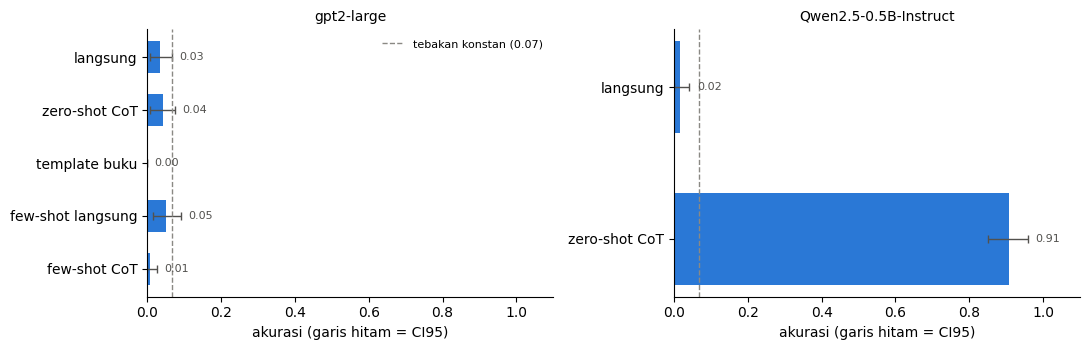

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for ax, label in zip(axes, [BOOK_LABEL, CHAT_LABEL]):
    styles = [s for (m, s) in RESULTS if m == label]
    acc = np.array([RESULTS[(label, s)]["correct"].mean() for s in styles])
    err = np.array([ci95(RESULTS[(label, s)]["correct"]) for s in styles])
    y = np.arange(len(styles))[::-1]
    ax.barh(y, acc, color="#2a78d6", height=0.6)
    ax.errorbar(acc, y, xerr=[acc - err[:, 0], err[:, 1] - acc], fmt="none", ecolor="#52514e", capsize=3, linewidth=1)
    for yi, a, hi in zip(y, acc, err[:, 1]):
        ax.text(hi + 0.02, yi, f"{a:.2f}", va="center", fontsize=8, color="#52514e")
    ax.axvline(baseline, color="#8a8984", linestyle="--", linewidth=1, label=f"tebakan konstan ({baseline:.2f})")
    ax.set_yticks(y)
    ax.set_yticklabels(styles)
    ax.set_title(label, fontsize=10)
    ax.set_xlim(0, 1.1)
    ax.set_xlabel("akurasi (garis hitam = CI95)")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

**Dua model berukuran sebanding, dua cerita yang berlawanan** *(validasi lokal, n = 30; tebakan konstan '6' benar di 0,100)*.

Qwen yang diminta langsung menjawab benar di 0 dari 30 soal, dengan rata-rata 3 token per jawaban. Dengan CoT, 28 dari 30 soal benar (0,933, CI95 0,833 sampai 1,000). Selisih berpasangannya +0,933 dan seluruh rentangnya jauh dari nol: di sini CoT jelas menolong. Harganya juga terlihat di kolom token: sekitar 179 token per soal, kira-kira 60 kali jawaban langsung.

GPT-2 large tidak pernah melampaui tebakan konstan. Gaya terbaiknya, few-shot langsung, tepat menyamai baseline (0,100), dan menambahkan rantai ke contoh yang sama justru menurunkan akurasi ke 0,000; selisih -0,100 dengan CI95 -0,200 sampai 0,000, jadi tidak terbedakan dari nol. Kolom lain menjelaskan sebabnya:

- jawaban langsung dan zero-shot CoT kebanyakan hanya mengulang bilangan dari soal (19 dan 22 dari 30 soal);
- template buku tidak menghasilkan jawaban sama sekali (30 dari 30 jawaban tanpa angka), karena yang ditiru adalah label kosong;
- few-shot CoT meniru format contoh dan menulis 63 persamaan untuk 30 soal, tetapi hanya 9 di antaranya yang hitungannya benar, dan 6 dari 30 jawabannya adalah jawaban salah satu contoh.

GPT-2 large bisa meniru *bentuk* rantai penalaran tanpa melakukan penalarannya, persis yang dilaporkan Wei dkk. untuk model yang tidak cukup besar. Qwen berbeda bukan karena lebih besar; parameternya justru 36% lebih sedikit. Bedanya ada di data dan cara pelatihan: Qwen2.5 dilatih dengan data jauh lebih banyak yang memuat soal matematika, lalu di-fine-tune untuk mengikuti instruksi, dan menurut laporan teknisnya data fine-tuning itu memuat solusi matematika bertahap. Eksperimen ini tidak memisahkan mana yang paling berperan, karena model dasar Qwen tidak diuji. Yang jelas, bagi model yang tidak dilatih untuk itu, dorongan *Let's think step by step* saja tidak cukup; itulah sisi lain makalah *CoT Collection* tadi. Dengan 30 soal rentang CI95 masih lebar; di GPU, 120 soal akan mempersempitnya.

## Menilai output CoT

Buku menilai output CoT dari dua sisi: apakah jawaban akhirnya benar, dan apakah langkah-langkahnya masuk akal. Kerangkanya tepat, tetapi isinya belum ada.

> **Listing buku: `evaluate_cot_output` dengan fungsi kosong**
>
> ```python
> def evaluate_cot_output(output, correct_answer):
>     final_answer = extract_final_answer(output)
>     answer_correct = final_answer == correct_answer
> ...
> def extract_final_answer(output):
>     # Implement logic to extract the final answer from the CoT output
>     pass
> ```
>
> `extract_final_answer` dan `evaluate_reasoning_steps` hanya berisi `pass`, jadi keduanya mengembalikan `None`, dan `None == 60` selalu `False`: jawaban yang benar pun dinilai salah. Mengisi ekstraktor dengan regex belum cukup, karena regex menghasilkan string, dan `'60' == 60` juga `False` di Python. Contoh pemakaiannya pun memanggil `solve_math_problem` buku yang gagal tadi. `extract_final_answer` sudah kita isi di sel helper teks dan dipakai sejak eksperimen tadi; sel berikut mengisi `evaluate_reasoning_steps`, membandingkan angka dengan angka, lalu menjalankan contoh buku (soal kereta 180 km dalam 3 jam, kunci 60) dengan `solve_math_problem` versi kerja.

In [16]:
def evaluate_reasoning_steps(output):
    """Skor penalaran = proporsi persamaan yang hitungannya benar; None bila tak ada persamaan yang terbaca."""
    checks = check_equations(output)
    if not checks:
        return None
    return float(np.mean([same_number(claimed, value) for _, claimed, value in checks]))


def evaluate_cot_output(output, correct_answer):
    final_answer = extract_final_answer(output)
    return {
        "final_answer": final_answer,
        "answer_correct": same_number(final_answer, float(correct_answer)),   # angka lawan angka, bukan string
        "reasoning_score": evaluate_reasoning_steps(output),
    }


cot_output = cut_reply(solve_math_problem(book_model, book_tok, train))   # contoh buku: soal kereta 180 km / 3 jam
print(f"output {BOOK_LABEL}: {cot_output.strip()[:160]!r}")
print("   ->", evaluate_cot_output(cot_output, 60))
for text in ["Average Speed = 180 km / 3 hours = 60 km/h. Therefore, the answer is 60 km/h.",
             "180 / 3 = 60. The answer is 60.",
             "180 / 3 = 50. The answer is 50."]:
    print(f"{text!r}\n   -> {evaluate_cot_output(text, 60)}")

output gpt2-large: '1) First, we need to...\n2) Next, we should...\n3) Then, we can...\n4) Finally, we can...\nTherefore, the answer is...'
   -> {'final_answer': None, 'answer_correct': False, 'reasoning_score': None}
'Average Speed = 180 km / 3 hours = 60 km/h. Therefore, the answer is 60 km/h.'
   -> {'final_answer': 60.0, 'answer_correct': True, 'reasoning_score': None}
'180 / 3 = 60. The answer is 60.'
   -> {'final_answer': 60.0, 'answer_correct': True, 'reasoning_score': 1.0}
'180 / 3 = 50. The answer is 50.'
   -> {'final_answer': 50.0, 'answer_correct': False, 'reasoning_score': 0.0}


Baris pertama adalah contoh buku dengan model sungguhan. GPT-2 large, diberi template untuk soal kereta 180 km dalam 3 jam, lagi-lagi hanya menyalin label kosong *(validasi lokal)*. Tidak ada angka di sana, jadi `final_answer` bernilai `None` dan jawabannya dinilai salah, kali ini dengan alasan yang benar.

Tiga baris berikutnya menguji penilainya sendiri. Kalimat bersatuan *180 km / 3 hours = 60 km/h* dinilai benar jawabannya, tetapi `reasoning_score`-nya `None`: pemeriksa persamaan hanya membaca ekspresi angka, dan kata *km* serta *hours* di antara angka membuat ekspresi itu tak terbaca. Rantai `180 / 3 = 60` mendapat skor 1,0, sedangkan `180 / 3 = 50` ditolak dua kali, jawabannya salah dan hitungannya salah. Skor penalaran ini sengaja sederhana: ia memeriksa aritmetika, bukan apakah langkahnya masuk akal untuk soal itu.

### Under the hood: seberapa andal ekstraktor jawaban?

Komentar di listing buku menyarankan dua cara mengekstrak jawaban: *parsing the last line* atau *looking for specific phrases*. `extract_final_answer` sudah menentukan semua angka akurasi tadi, jadi sekarang saatnya mengujinya, bersama dua saran buku, pada teks yang jawabannya kita tahu pasti. Delapan teks berikut mewakili pola yang sudah kita lihat (rantai benar, label langkah kosong seperti output template buku, format `\boxed{}` yang dipakai Qwen) dan pola yang wajar muncul di jawaban model (jawaban akhir salah, teks tanpa angka, jawaban tanpa frasa *answer is*, angka susulan, dan cek balik).

In [17]:
q_demo, steps_demo = EVAL[0]
g = steps_demo[-1][3]
ORACLE = [   # (kasus, teks, angka yang memang ditulis sebagai jawaban akhir; None = tidak ada jawaban)
    ("rantai benar", chain_text(steps_demo), g),
    ("jawaban akhir salah", chain_text(steps_demo).rsplit(" ", 1)[0] + f" {fmt(g + 1)}.", g + 1),
    ("tanpa angka", "First, we need to read the problem carefully.", None),
    ("label langkah saja", "1) First, we need to...\n2) Next, we should...", None),
    ("benar tanpa frasa", f"So the result is {fmt(g)} in total.", g),
    ("benar, lalu angka lain", f"The answer is {fmt(g)}. That took {fmt(g + 7)} minutes.", g),
    ("jawaban di \\boxed{}", f"So we get {fmt(g)}.\n\n\\boxed{{{fmt(g)}}}", g),
    ("jawaban, lalu cek balik", f"So there are {fmt(g)} left. Check: {fmt(g)} + 3 = {fmt(g + 3)}.", g),
]
EXTRACTORS = {
    "angka terakhir": lambda t: (numbers(t) or [None])[-1],
    "setelah 'answer is'": lambda t: (lambda m: float(m[-1]) if m else None)(ANSWER.findall(t)),
    "extract_final_answer": extract_final_answer,
}
print(f"{'kasus':<26}" + "".join(f"{k:>24}" for k in EXTRACTORS))
passed = Counter()
for case, text, want in ORACLE:
    cells = []
    for name, extract in EXTRACTORS.items():
        got = extract(text)
        ok = (got is None and want is None) or same_number(got, want)
        passed[name] += ok
        cells.append(f"{'-' if got is None else fmt(got)} {'tepat' if ok else 'KELIRU'}")
    print(f"{case:<26}" + "".join(f"{c:>24}" for c in cells))
print(f"{'lolos':<26}" + "".join(f"{f'{passed[k]}/{len(ORACLE)}':>24}" for k in EXTRACTORS))

kasus                               angka terakhir     setelah 'answer is'    extract_final_answer
rantai benar                              40 tepat                40 tepat                40 tepat
jawaban akhir salah                       41 tepat                41 tepat                41 tepat
tanpa angka                                - tepat                 - tepat                 - tepat
label langkah saja                        2 KELIRU                 - tepat                 - tepat
benar tanpa frasa                         40 tepat                - KELIRU                40 tepat
benar, lalu angka lain                   47 KELIRU                40 tepat                40 tepat
jawaban di \boxed{}                       40 tepat                - KELIRU                40 tepat
jawaban, lalu cek balik                  43 KELIRU                - KELIRU               43 KELIRU
lolos                                          5/8                     5/8                     7/8


Tiga ekstraktor, tiga pola kegagalan. *Angka terakhir*, saran pertama buku, lolos 5 dari 8: ia membaca label *2)* sebagai jawaban, membaca 47 dari kalimat sesudah jawaban, dan 43 dari cek balik. *Setelah 'answer is'*, saran kedua, juga lolos 5 dari 8: ia aman dari label dan angka susulan, tetapi buta terhadap jawaban yang ditulis tanpa frasa itu, termasuk format `\boxed{}`. `extract_final_answer` menggabungkan keduanya dan lolos 7 dari 8, tetapi tetap kalah pada cek balik: kalimat *Check: 40 + 3 = 43* membuatnya menjawab 43.

Tidak ada ekstraktor yang sempurna. Karena itu akurasi di notebook ini selalu dibaca bersama kolom "tanpa jawaban" dan contoh teks aslinya, bukan sebagai angka yang berdiri sendiri.

### Penjelasan yang lancar belum tentu benar

Dengan ekstraktor dan pemeriksa persamaan, jawaban CoT Qwen dari eksperimen tadi bisa dibedah. Setiap jawaban masuk ke satu kelompok: benar atau salah, lalu apakah semua hitungannya benar, ada hitungan yang salah, atau tidak ada persamaan angka yang terbaca.

In [18]:
def classify(text, pred, answer):
    checks = check_equations(text)
    wrong_steps = [c for c in checks if not same_number(c[1], c[2])]
    right = same_number(pred, answer)
    if not checks:
        return ("benar" if right else "salah") + ", tanpa persamaan terbaca"
    return ("benar" if right else "salah") + (", ada hitungan salah" if wrong_steps else ", semua hitungan benar")


cot = RESULTS[(CHAT_LABEL, "zero-shot CoT")]
kinds = [classify(t, p, a) for t, p, a in zip(cot["text"], cot["pred"], gold)]
for kind, n in sorted(Counter(kinds).items()):
    print(f"{kind:<36} {n:>4} soal ({n / len(kinds):.3f})")

for wanted in ["salah, semua hitungan benar", "salah, tanpa persamaan terbaca", "salah, ada hitungan salah", "benar, ada hitungan salah"]:
    if wanted in kinds:
        k = kinds.index(wanted)
        bad = [f"{e} = {fmt(c)} (seharusnya {fmt(v)})" for e, c, v in check_equations(cot["text"][k]) if not same_number(c, v)]
        read = "-" if cot["pred"][k] is None else fmt(cot["pred"][k])
        print(f"\n--- contoh '{wanted}' | kunci {fmt(gold[k])}, jawaban terbaca {read} | hitungan salah: {bad or '-'}")
        print(questions[k])
        print(cot["text"][k][:1500])

benar, ada hitungan salah               1 soal (0.008)
benar, semua hitungan benar           102 soal (0.850)
benar, tanpa persamaan terbaca          6 soal (0.050)
salah, ada hitungan salah               1 soal (0.008)
salah, semua hitungan benar             7 soal (0.058)
salah, tanpa persamaan terbaca          3 soal (0.025)

--- contoh 'salah, semua hitungan benar' | kunci 6, jawaban terbaca 36 | hitungan salah: -
At lunch a waiter had 7 customers and 5 of them didn't leave a tip. If he got $3 each from the ones who did tip, how much money did he earn?
To determine how much money the waiter earned, we need to follow these steps:

1. **Calculate the number of customers who did tip:**
   - Total customers: 7
   - Customers who didn't tip: 5
   - Customers who tipped: \( 7 - 5 = 2 \)

2. **Calculate the total amount of money earned from the customers who tipped:**
   - Each customer who tipped received $3.
   - Total money from tipped customers: \( 2 \times 3 = 6 \)

3. **Calculate th

*(validasi lokal, n = 30)* Dari 28 jawaban yang benar, 27 memuat hitungan yang terbaca, dan semuanya benar. Dari dua jawaban yang salah, satu memuat lima hitungan yang semuanya benar, dan satu lagi tidak memuat persamaan angka yang bisa diperiksa. Keduanya dicetak di output.

Yang pertama adalah soal pelayan: 7 pelanggan, 5 tidak memberi tip, dan pelayan mendapat $3 dari setiap pelanggan yang memberi tip. Qwen menghitung `7 - 5 = 2` dan `2 × 3 = 6`, yang sudah merupakan jawaban benar, lalu melanjutkan dengan `7 × 3 = 21`, `5 × 3 = 15`, dan `21 + 15 = 36`, dan menutup dengan *The answer is 36*. Kelima persamaannya benar; yang salah adalah rencananya. Jawaban salah yang kedua (soal kebun Nancy, kunci 6, contoh berikutnya di output) mengabaikan 52 benih awal dan menyusun persamaan aljabar rapi `28 = 4x`, sehingga menjawab 7; persamaan dengan huruf seperti ini tidak terbaca oleh `check_equations`.

Pelajarannya dua. Penjelasan yang lancar dengan hitungan yang benar bukan bukti bahwa jawabannya benar: pemeriksa aritmetika meloloskan jawaban pelayan, dan pada jawaban Nancy ia tidak membaca apa pun untuk dinilai. Dan pada model ini, sumber kesalahannya bukan berhitung, melainkan menentukan *apa* yang harus dihitung, sesuatu yang tidak bisa diperiksa dengan regex.

## Keterbatasan CoT

Buku menyebut empat keterbatasan: biaya token dan waktu, potensi perambatan galat dalam penalaran bertahap, ketergantungan pada kualitas prompt awal, dan tidak cocok untuk semua jenis soal. Dua sudah terlihat. Biaya ada di kolom token/soal: Qwen menjawab langsung dengan rata-rata 3 token dan dengan CoT sekitar 179 token per soal *(validasi lokal, n = 30)*, kira-kira 60 kali lipat. Waktu komputasi mengikuti jumlah token yang dihasilkan, jadi notebook ini mengukur biaya dalam token, yang tidak bergantung pada hardware. Ketergantungan pada prompt terlihat dari template buku: karena yang dicontohkan hanya label kosong, semua output GPT-2 large tidak memuat jawaban. Keterbatasan keempat, bahwa CoT tidak cocok untuk semua soal, diuji di bagian CoT adaptif. Yang belum diuji adalah perambatan galat.

### Under the hood: apakah galat di langkah 1 merambat?

Untuk menguji perambatan galat kita butuh rantai yang langkah pertamanya salah, dan cara paling bersih adalah **memberikan** rantainya, bukan menunggu model menulisnya sendiri. Rantai ditulis di bagian jawaban, lalu kita lihat angka mana yang paling disukai model sebagai lanjutannya. "Paling disukai" diukur dengan *log-probability*: jumlah log-peluang token kandidat, misalnya ` 39.`, setelah prefix. Kandidatnya sama di semua kondisi: kunci, jawaban rantai salah, hasil langkah 1 yang benar dan yang salah, serta semua bilangan di soal.

Lima kondisi dibandingkan pada 120 soal MultiArith (ukuran GPU) yang tidak dipakai di eksperimen sebelumnya:
- *tanpa rantai*: langsung `The answer is`;
- *rantai benar*: kedua langkah benar, lalu `The answer is`;
- *rantai salah di langkah 1*: hasil langkah 1 digeser 1-3 satuan, langkah 2 dihitung benar dari angka yang salah, lalu `The answer is`;
- *rantai benar tanpa hasil akhir*: langkah 1 benar, langkah 2 berhenti di `a op b =`, jadi model harus menghitung sendiri;
- *rantai salah tanpa hasil akhir*: langkah 1 salah, langkah 2 berhenti di `a op b =` dengan angka yang salah itu. Inilah uji perambatan yang sebenarnya: apakah model menghitung dari angka salah yang tertulis, atau kembali ke jawaban yang benar?

Soal dipilih agar keempat angka rantai saling berbeda dan tidak ada di soal, sehingga setiap pilihan model jatuh tepat ke satu kategori.

In [19]:
def corrupt(steps, rng):
    """Salah hitung di langkah 1 (geser 1-3), lalu langkah 2 dihitung benar dari angka yang salah."""
    (a, op1, b, r1), (x, op2, y, r2) = steps
    left = x == r1
    for d in rng.sample([1, 2, -1, -2, 3, -3], 6):
        r1_wrong = r1 + d
        if r1_wrong <= 0:
            continue
        x2, y2 = (r1_wrong, y) if left else (x, r1_wrong)
        r2_wrong = OPS[op2](x2, y2)
        if r2_wrong > 0 and float(r2_wrong).is_integer() and r2_wrong != r2:
            return [(a, op1, b, r1_wrong), (x2, op2, y2, r2_wrong)]
    return None


rng = random.Random(SEED + 1)
PROP = []
for q, steps in PROP_POOL:
    wrong = corrupt(steps, rng)
    if wrong is None:
        continue
    keys = {steps[0][3], steps[1][3], wrong[0][3], wrong[1][3]}
    integer_chain = all(float(s[3]).is_integer() and s[3] > 0 for s in steps)
    if len(keys) == 4 and integer_chain and not keys & set(numbers(q)):   # empat angka rantai saling beda dan tak ada di soal
        PROP.append((q, steps, wrong))
    if len(PROP) == N_PROP:
        break

CONDITIONS = ["tanpa rantai", "rantai benar", "rantai salah di langkah 1", "rantai benar tanpa hasil akhir",
              "rantai salah tanpa hasil akhir"]


def reply_prefix(condition, steps, wrong):
    if condition == "tanpa rantai":
        return "The answer is"
    if condition == "rantai benar":
        return f"{step_text(steps[0])}. {step_text(steps[1])}. The answer is"
    if condition == "rantai salah di langkah 1":
        return f"{step_text(wrong[0])}. {step_text(wrong[1])}. The answer is"
    if condition == "rantai benar tanpa hasil akhir":
        a, op, b, _ = steps[1]
        return f"{step_text(steps[0])}. {fmt(a)} {op} {fmt(b)} ="      # langkah terakhir harus dihitung model
    a, op, b, _ = wrong[1]
    return f"{step_text(wrong[0])}. {fmt(a)} {op} {fmt(b)} ="          # dihitung model, dari langkah 1 yang salah


def full_prefix(kind, q, reply):
    return f"Q: {q}\nA: {reply}" if kind == "book" else chat_prompt(chat_tok, q, reply_start=reply)


CHOICE = {}
for label, model, tokenizer, kind in [(BOOK_LABEL, book_model, book_tok, "book"), (CHAT_LABEL, chat_model, chat_tok, "chat")]:
    t0 = time.time()
    for condition in CONDITIONS:
        prefixes, conts, owner = [], [], []
        for k, (q, steps, wrong) in enumerate(PROP):
            candidates = sorted({steps[1][3], wrong[1][3], steps[0][3], wrong[0][3], *numbers(q)})
            prefix = full_prefix(kind, q, reply_prefix(condition, steps, wrong))
            for c in candidates:
                prefixes.append(prefix)
                conts.append(f" {fmt(c)}.")
                owner.append((k, c))
        best = {}
        for (k, c), s in zip(owner, score_continuations(model, tokenizer, prefixes, conts)):
            if k not in best or s > best[k][1]:
                best[k] = (c, s)
        CHOICE[(label, condition)] = [best[k][0] for k in range(len(PROP))]
    print(f"{label}: {len(PROP)} soal x {len(CONDITIONS)} kondisi, {time.time() - t0:.0f} s")
for condition in ["rantai salah di langkah 1", "rantai salah tanpa hasil akhir"]:
    print(f"contoh prefix '{condition}':", repr(full_prefix("book", PROP[0][0], reply_prefix(condition, *PROP[0][1:]))))

gpt2-large: 120 soal x 5 kondisi, 123 s
Qwen2.5-0.5B-Instruct: 120 soal x 5 kondisi, 107 s
contoh prefix 'rantai salah di langkah 1': 'Q: A pet store had 38 siamese cats and 25 house cats. During a sale they sold 45 cats. How many cats do they have left?\nA: 38 + 25 = 61. 61 - 45 = 16. The answer is'
contoh prefix 'rantai salah tanpa hasil akhir': 'Q: A pet store had 38 siamese cats and 25 house cats. During a sale they sold 45 cats. How many cats do they have left?\nA: 38 + 25 = 61. 61 - 45 ='


In [20]:
boot_p = np.random.default_rng(SEED).integers(0, len(PROP), (2000, len(PROP)))
CATS = {
    "kunci (benar)": lambda c, s, w: c == s[1][3],
    "jawaban rantai salah": lambda c, s, w: c == w[1][3],
    "hasil langkah 1 benar": lambda c, s, w: c == s[0][3],
    "hasil langkah 1 salah": lambda c, s, w: c == w[0][3],
    "angka lain di soal": lambda c, s, w: c not in (s[1][3], w[1][3], s[0][3], w[0][3]),
}
SHARE = {}
for label in [BOOK_LABEL, CHAT_LABEL]:
    print(f"\n{label}: proporsi soal per jawaban yang dipilih (log-prob tertinggi) [CI95]")
    print(f"{'kondisi':<32}" + "".join(f"{c:>24}" for c in CATS))
    for condition in CONDITIONS:
        cells = []
        for name, test in CATS.items():
            hit = np.array([test(c, s, w) for c, (q, s, w) in zip(CHOICE[(label, condition)], PROP)], float)
            lo, hi = np.percentile(hit[boot_p].mean(1), [2.5, 97.5])
            SHARE[(label, condition, name)] = hit.mean()
            cells.append(f"{hit.mean():.3f} [{lo:.2f}; {hi:.2f}]")
        print(f"{condition:<32}" + "".join(f"{c:>24}" for c in cells))
    follow_right = np.array([c in (s[1][3], s[0][3]) for c, (q, s, w) in zip(CHOICE[(label, "rantai benar")], PROP)], float)
    follow_wrong = np.array([c in (w[1][3], w[0][3]) for c, (q, s, w) in zip(CHOICE[(label, "rantai salah di langkah 1")], PROP)], float)
    d = follow_wrong - follow_right
    lo, hi = np.percentile(d[boot_p].mean(1), [2.5, 97.5])
    print(f"mengikuti angka rantai yang diberikan: rantai benar {follow_right.mean():.3f}, rantai salah {follow_wrong.mean():.3f}, "
          f"selisih {d.mean():+.3f} [{lo:+.3f}; {hi:+.3f}]")


gpt2-large: proporsi soal per jawaban yang dipilih (log-prob tertinggi) [CI95]
kondisi                                    kunci (benar)    jawaban rantai salah   hasil langkah 1 benar   hasil langkah 1 salah      angka lain di soal
tanpa rantai                          0.000 [0.00; 0.00]      0.000 [0.00; 0.00]      0.008 [0.00; 0.03]      0.025 [0.00; 0.06]      0.967 [0.93; 0.99]
rantai benar                          0.992 [0.97; 1.00]      0.000 [0.00; 0.00]      0.008 [0.00; 0.03]      0.000 [0.00; 0.00]      0.000 [0.00; 0.00]
rantai salah di langkah 1             0.000 [0.00; 0.00]      1.000 [1.00; 1.00]      0.000 [0.00; 0.00]      0.000 [0.00; 0.00]      0.000 [0.00; 0.00]
rantai benar tanpa hasil akhir        0.142 [0.08; 0.21]      0.042 [0.01; 0.08]      0.092 [0.04; 0.15]      0.067 [0.03; 0.12]      0.658 [0.57; 0.74]
rantai salah tanpa hasil akhir        0.042 [0.01; 0.08]      0.083 [0.04; 0.13]      0.042 [0.01; 0.08]      0.150 [0.09; 0.22]      0.683 [0.60; 0.76]
me

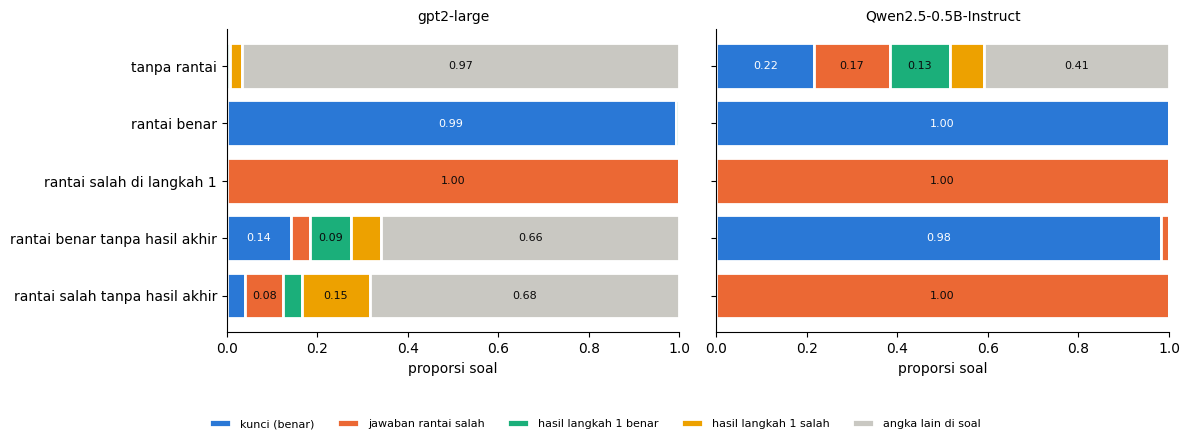

In [21]:
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#c9c8c2"]   # abu-abu = angka lain di soal
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, label in zip(axes, [BOOK_LABEL, CHAT_LABEL]):
    for row, condition in enumerate(CONDITIONS[::-1]):
        start = 0.0
        for j, name in enumerate(CATS):
            v = SHARE[(label, condition, name)]
            ax.barh(row, v, left=start, color=colors[j], edgecolor="white", linewidth=2,
                    label=name if row == 0 else None)
            if v >= 0.08:
                ax.text(start + v / 2, row, f"{v:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if j == 0 else "#0b0b0b")
            start += v
    ax.set_yticks(range(len(CONDITIONS)))
    ax.set_yticklabels(CONDITIONS[::-1])
    ax.set_xlim(0, 1)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("proporsi soal")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, ncol=5, fontsize=8, frameon=False, loc="lower center")
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

*(validasi lokal, n = 30)* Mulai dari dua baris yang hasilnya paling sederhana. Bila rantai lengkap diberikan, kedua model menyalin hasil akhir yang tertulis: kunci di 30 dari 30 soal bila rantainya benar, jawaban rantai yang salah di 30 dari 30 soal bila langkah 1-nya salah. Tidak ada model yang menolak hasil yang salah.

Dua baris terakhir lebih menarik, karena di sana model harus menghitung sendiri. Dengan langkah 1 yang benar, Qwen melengkapi hitungan terakhir dengan benar di 30 dari 30 soal, sedangkan GPT-2 large hanya di 3 soal (0,100) dan dua pertiga pilihannya adalah bilangan lain dari soal. Dengan langkah 1 yang salah, Qwen menghitung dari angka salah itu di 30 dari 30 soal: ia mengerjakan `4 * 9` dengan benar, padahal 9 seharusnya 10. Tidak sekali pun ia kembali ke kunci. GPT-2 large tetap kebanyakan memilih bilangan lain dari soal (0,733), jadi pada model ini tidak ada hitungan yang bisa "tertular".

Inilah keterbatasan perambatan galat dalam bentuk yang paling bersih. Qwen mampu menghitung langkah 2 dari langkah 1, dan justru karena itu galat langkah 1 terbawa utuh ke jawabannya: rantai CoT adalah konteks yang diikuti, bukan pemeriksaan. Batas cakupannya: rantai di sini ditulis untuk model dan jawabannya dibaca lewat log-prob; bila model diminta memeriksa ulang langkahnya secara eksplisit, hasilnya bisa lain, dan itu tidak diuji di sini.

## CoT dinamis

Buku menawarkan CoT dinamis untuk mengatasi sebagian keterbatasan itu: prompt tumbuh satu langkah per iterasi (`Step 1:`, `Step 2:`, ...), dan loop berhenti begitu langkah baru memuat *Therefore, the final answer is*, atau setelah `max_steps=5`. Prosa buku juga memperingatkan bahwa prompt yang terus tumbuh bisa melewati batas token model.

> **Listing buku: `dynamic_cot` (gagal, dan setelah ditambal tetap crash)**
>
> ```python
> inputs = tokenizer(prompt, return_tensors="pt")
> outputs = model.generate(
>     inputs, max_length=len(prompt) + 100,
>     num_return_sequences=1
> )
> ```
>
> Baris `generate` memicu `AttributeError` yang sama. Bila hanya itu yang ditambal (`**inputs`), masalah kedua muncul: `len(prompt)` menghitung **karakter**, sedangkan `max_length` menghitung **token** prompt ditambah teks baru. Di langkah 1, prompt soal resep 154 karakter = 41 token GPT-2, jadi model boleh menulis 213 token, bukan 100. Jatah itu membengkak tiap langkah. Saat diverifikasi dengan GPT-2 124M (CPU, transformers 5.20), teks langkah 1 sudah memuat kata *Step* 16 kali, dan di langkah 3 prompt 985 token dengan `max_length` 3.431 melewati 1.024 posisi GPT-2: `IndexError: index out of range in self`. Peringatan buku soal batas token benar, tetapi kodenya tidak memotong apa pun; ia crash dan semua langkah yang sudah ditulis ikut hilang.

Versi kerja di bawah memakai `max_new_tokens=60` per langkah (buku bermaksud 100; dikurangi karena satu langkah jarang butuh lebih, dan teks sesudah langkah itu dibuang), memotong teks bila model mulai menulis langkah berikutnya sendiri (jadi satu iterasi benar-benar satu langkah), dan berhenti sebelum konteks penuh. Intinya ada di `dynamic_cot_batch`, yang mengerjakan banyak soal sekaligus di GPU; `dynamic_cot` membungkusnya dengan antarmuka buku, satu soal masuk dan prompt akhir keluar. Sel berikut menjalankan contoh buku, soal resep, lewat antarmuka itu.

In [22]:
STOP = "Therefore, the final answer is"
NEXT_STEP = re.compile(r"\n\s*(?:Step\s*\d+\s*:|Problem:)")


def dynamic_cot_batch(model, tokenizer, base_prompts, max_steps=5, step_tokens=60):
    """Satu langkah per iterasi untuk sekumpulan prompt; berhenti di frasa STOP, setelah max_steps, atau sebelum konteks penuh."""
    prompts = list(base_prompts)
    active, why, spent = list(range(len(prompts))), {}, [0] * len(prompts)
    for step in range(1, max_steps + 1):
        for i in active:
            prompts[i] += f"\n\nStep {step}:"
        full = [i for i in active if len(tokenizer(prompts[i])["input_ids"]) + step_tokens > context_limit(model)]
        for i in full:
            why[i] = "konteks penuh"
        active = [i for i in active if i not in full]
        if not active:
            break
        texts, n_tok = generate(model, tokenizer, [prompts[i] for i in active], step_tokens)
        still_going = []
        for i, text, n in zip(active, texts, n_tok):
            one_step = NEXT_STEP.split(text)[0].rstrip()    # potong bila model menulis langkah berikutnya sendiri
            prompts[i] += one_step
            spent[i] += n
            if STOP in one_step:
                why[i] = f"frasa berhenti di langkah {step}"
            else:
                still_going.append(i)
        active = still_going
    for i in active:
        why[i] = "max_steps habis"
    return prompts, why, spent


def dynamic_cot(model, tokenizer, problem, max_steps=5):
    """Antarmuka buku: satu soal masuk, prompt akhir keluar."""
    prompts, _, _ = dynamic_cot_batch(model, tokenizer, [f"Problem: {problem}\n\nLet's solve this step by step:"], max_steps)
    return prompts[0]


print(dynamic_cot(book_model, book_tok, recipe))      # contoh pemakaian buku, soal resep

Problem: If a recipe calls for 2 cups of flour for 8 servings, how many cups of flour are needed for 12 servings?

Let's solve this step by step:

Step 1: Determine the number of cups of flour needed for 8 servings.

Step 2: Determine the number of cups of flour needed for 12 servings.

Step 3: Determine the number of cups of flour needed for 8 servings.

Step 4: Determine the number of cups of flour needed for 12 servings.

Step 5: Determine the number of cups of flour needed for 8 servings.


Lewat antarmuka buku, GPT-2 large kini menulis tepat satu langkah per iterasi, tetapi isinya kosong *(validasi lokal)*: *Determine the number of cups of flour needed for 8 servings* dan *... for 12 servings* bergantian sampai langkah 5, tanpa satu hitungan pun (angka yang muncul hanya 8 dan 12 dari soal), dan loop berhenti karena `max_steps` habis. Frasa *Therefore, the final answer is* tidak pernah muncul, karena tidak ada bagian prompt yang meminta atau mencontohkannya.

Sel berikut membandingkan tiga varian pada 16 soal (ukuran GPU): prompt buku apa adanya; prompt buku ditambah satu contoh yang ditutup frasa berhenti, dengan jawaban contoh 6; dan Qwen yang diminta memakai format langkah serta frasa berhenti.

In [23]:
EXAMPLE = ("Problem: Tom has 3 apples. He buys 5 more apples and then eats 2. How many apples does Tom have?\n\n"
           "Let's solve this step by step:\n\nStep 1: Tom starts with 3 apples and buys 5 more, so 3 + 5 = 8.\n\n"
           "Step 2: He eats 2, so 8 - 2 = 6.\n\nStep 3: Therefore, the final answer is 6.\n\n")
dyn_questions = questions[:N_DYN]
dyn_gold = gold[:N_DYN]
chat_dynamic = (f"Solve it step by step. Write one step per line as 'Step k: ...'. "
                f"When you are done, write '{STOP} <number>.'")
VARIANTS = {
    f"{BOOK_LABEL}, prompt buku": (book_model, book_tok,
        [f"Problem: {q}\n\nLet's solve this step by step:" for q in dyn_questions]),
    f"{BOOK_LABEL}, + 1 contoh": (book_model, book_tok,
        [EXAMPLE + f"Problem: {q}\n\nLet's solve this step by step:" for q in dyn_questions]),
    f"{CHAT_LABEL}, minta frasa": (chat_model, chat_tok,
        [chat_prompt(chat_tok, f"Problem: {q}\n{chat_dynamic}", reply_start="Let's solve this step by step:")
         for q in dyn_questions]),
}
print(f"{'varian':<38}{'token baru/soal':>16}{'akurasi':>9}{'= 6 (jawaban contoh)':>22}   alasan berhenti")
DYN = {}
for name, (model, tokenizer, base) in VARIANTS.items():
    final_prompts, why, spent = dynamic_cot_batch(model, tokenizer, base)
    own = [p[len(b):] for p, b in zip(final_prompts, base)]     # teks soal itu sendiri, tanpa contoh di depannya
    pred = [extract_final_answer(t) for t in own]
    DYN[name] = own
    reasons = ", ".join(f"{k}: {v}" for k, v in sorted(Counter(why.values()).items()))
    copied = f"{np.mean([same_number(p, 6.0) for p in pred]):.3f}" if base[0].startswith(EXAMPLE) else "-"
    print(f"{name:<38}{np.mean(spent):>16.0f}{np.mean([same_number(p, a) for p, a in zip(pred, dyn_gold)]):>9.3f}"
          f"{copied:>22}   {reasons}")
print(f"kunci yang kebetulan 6: {int(np.sum(dyn_gold == 6))} dari {N_DYN} soal")
for name, own in DYN.items():
    print(f"\n--- {name}, soal pertama (kunci {fmt(dyn_gold[0])}):\n{own[0][:420]}")

varian                                 token baru/soal  akurasi  = 6 (jawaban contoh)   alasan berhenti
gpt2-large, prompt buku                            300    0.000                     -   max_steps habis: 16
gpt2-large, + 1 contoh                             195    0.000                 0.188   frasa berhenti di langkah 3: 14, max_steps habis: 2
Qwen2.5-0.5B-Instruct, minta frasa                 210    0.688                     -   frasa berhenti di langkah 2: 4, frasa berhenti di langkah 3: 3, frasa berhenti di langkah 4: 3, frasa berhenti di langkah 5: 4, max_steps habis: 2
kunci yang kebetulan 6: 2 dari 16 soal

--- gpt2-large, prompt buku, soal pertama (kunci 40):


Step 1: Find the number of students who want the red apples and the green apples.

Step 2: Find the number of students who want the red apples and the green apples.

Step 3: Find the number of students who want the red apples and the green apples.

Step 4: Find the number of students who want the red apples and the 

*(validasi lokal, n = 6: terlalu sedikit untuk angka akurasi yang presisi, tetapi polanya jelas.)* Dengan prompt buku, GPT-2 large tidak pernah berhenti sendiri: keenam soal menghabiskan 5 langkah × 60 token = 300 token, dengan akurasi 0. Dengan satu contoh, frasa berhenti memang muncul, dan selalu di langkah 3, persis jumlah langkah contoh Tom. Bentuk contoh ditiru utuh: soal pertama ditutup *Therefore, the final answer is 42*, padahal 42 hanya bilangan pertama di soal (kuncinya 40). Akurasinya tetap 0, dan satu dari enam jawaban adalah 6, jawaban contoh. Qwen yang diminta format dan frasa berhenti menjawab benar 5 dari 6 soal dan berhenti lewat frasa di 5 soal.

Frasa berhenti hanya berguna bila model memang mengikuti instruksi atau contoh, dan contoh ikut membawa bentuk serta angkanya. CoT dinamis juga tidak gratis: Qwen memakai sekitar 208 token per soal di sini, sebanding dengan CoT sekali jalan tadi (sekitar 179 token), tanpa bukti bahwa memecah generasi per langkah menaikkan akurasinya.

In [24]:
del book_model, book_tok, VARIANTS   # GPT-2 large tidak dipakai lagi; bagian berikutnya hanya memakai Qwen
gc.collect()
if ON_GPU:
    torch.cuda.empty_cache()
    print(f"VRAM terpakai setelah GPT-2 large dilepas: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

VRAM terpakai setelah GPT-2 large dilepas: 2.0 GB


## Arah ke depan: CoT adaptif

Buku menutup dengan empat arah riset: CoT adaptif, multimodal, kolaboratif, dan meta-learning untuk CoT. Hanya yang pertama punya kode: nilai kompleksitas soal, pakai CoT rinci bila nilainya di atas 0,7, dan jawaban langsung bila tidak. Setelah melihat kolom token/soal, idenya masuk akal: CoT mahal, jadi pakai hanya bila perlu.

> **Listing buku: `adaptive_cot` dengan fungsi kosong**
>
> ```python
> def adaptive_cot(model, tokenizer, problem, complexity_threshold=0.7):
>     complexity = assess_problem_complexity(problem)
>     if complexity > complexity_threshold:
> ...
> def assess_problem_complexity(problem):
>     # Implement logic to assess problem complexity
>     pass
> ```
>
> Ketiga fungsi pembantunya hanya `pass`, sehingga `complexity` bernilai `None` dan `None > 0.7` memicu `TypeError: '>' not supported between instances of 'NoneType' and 'float'`. Prosa buku sendiri menyebut logika penilaiannya belum diimplementasikan. Sel berikut mengisi ketiganya seminimal mungkin dengan Qwen: kompleksitas = banyaknya bilangan di soal dibagi 3, CoT rinci = prompt CoT tadi, jawaban langsung = prompt langsung tadi. Agar biayanya terlihat, fungsi mengembalikan jawaban beserta jumlah token yang dipakai.

In [25]:
def assess_problem_complexity(problem):
    """Heuristik sederhana: banyaknya bilangan di soal dibagi 3, maksimum 1."""
    return min(len(numbers(problem)) / 3, 1.0)


def simple_solve(model, tokenizer, problem):
    texts, n_tok = generate(model, tokenizer, [chat_prompt(tokenizer, f"{problem}\n{DIRECT_INSTRUCTION}")], N_CHAT_DIRECT)
    return first_number(texts[0]), n_tok[0]


def detailed_cot(model, tokenizer, problem):
    texts, n_tok = generate(model, tokenizer, [chat_prompt(tokenizer, f"{problem}\n{COT_INSTRUCTION}")], N_CHAT_COT)
    return extract_final_answer(texts[0]), n_tok[0]


def adaptive_cot(model, tokenizer, problem, complexity_threshold=0.7):
    complexity = assess_problem_complexity(problem)
    if complexity > complexity_threshold:
        return detailed_cot(model, tokenizer, problem)     # soal kompleks: CoT
    return simple_solve(model, tokenizer, problem)         # soal sederhana: jawaban langsung


book_example = "What is the result of 25 divided by 5?"
print(f"kompleksitas {assess_problem_complexity(book_example):.2f} -> (jawaban, token) = "
      f"{adaptive_cot(chat_model, chat_tok, book_example)}")

kompleksitas 0.67 -> (jawaban, token) = (5.0, 1)


Soal contoh buku, *25 divided by 5*, punya dua bilangan, jadi kompleksitasnya 0,67 dan ia masuk jalur langsung; Qwen menjawab 5 dengan satu token *(validasi lokal)*. Apakah routing ini berguna pada banyak soal? Sel berikut mengujinya pada campuran 40 soal satu langkah sintetis (tambah atau kurang dua bilangan) dan 40 soal MultiArith dua langkah (ukuran GPU). Separuh soal satu langkah sengaja diberi bilangan pengecoh yang tidak dipakai, yaitu umur tokohnya, karena heuristik yang menghitung bilangan pasti tertipu olehnya. Jawaban untuk soal dua langkah diambil dari eksperimen tadi, jadi angkanya konsisten. Tiga strategi dibandingkan: selalu langsung, selalu CoT, dan adaptif.

In [26]:
def one_step_problem(rng, distractor):
    name = rng.choice(["Tom", "Anna", "Ben", "Lisa", "Sam", "Mia"])
    thing = rng.choice(["apples", "books", "pencils", "marbles", "cookies"])
    intro = f"{name} is {rng.randint(7, 12)} years old. " if distractor else ""   # bilangan yang tidak dipakai
    if rng.random() < 0.5:
        a, b = rng.randint(2, 9), rng.randint(2, 9)
        return intro + f"{name} has {a} {thing}. {name} gets {b} more {thing}. How many {thing} does {name} have now?", a + b
    a, b = rng.randint(10, 19), rng.randint(2, 9)
    return intro + f"{name} has {a} {thing}. {name} gives away {b} {thing}. How many {thing} does {name} have now?", a - b


rng = random.Random(SEED + 2)
simple = [one_step_problem(rng, distractor=k % 2 == 1) for k in range(N_SIMPLE)]   # separuh diberi umur sebagai pengecoh
simple_q = [q for q, _ in simple]
direct_texts, direct_tok = generate(chat_model, chat_tok, [chat_prompt(chat_tok, f"{q}\n{DIRECT_INSTRUCTION}") for q in simple_q], N_CHAT_DIRECT)
cot_texts, cot_tok = generate(chat_model, chat_tok, [chat_prompt(chat_tok, f"{q}\n{COT_INSTRUCTION}") for q in simple_q], N_CHAT_COT)
two_direct = RESULTS[(CHAT_LABEL, "langsung")]          # soal dua langkah: pakai ulang hasil eksperimen tadi
two_cot = RESULTS[(CHAT_LABEL, "zero-shot CoT")]

mixed_q = simple_q + questions[:N_SIMPLE]
mixed_gold = np.array([a for _, a in simple] + gold[:N_SIMPLE].tolist(), float)
is_two_step = np.array([False] * N_SIMPLE + [True] * N_SIMPLE)
direct_pred = [first_number(cut_reply(t)) for t in direct_texts] + two_direct["pred"][:N_SIMPLE]
cot_pred = [extract_final_answer(cut_reply(t)) for t in cot_texts] + two_cot["pred"][:N_SIMPLE]
direct_cost = np.array(direct_tok + two_direct["tokens"][:N_SIMPLE].tolist())
cot_cost = np.array(cot_tok + two_cot["tokens"][:N_SIMPLE].tolist())
direct_ok = np.array([same_number(p, a) for p, a in zip(direct_pred, mixed_gold)])
cot_ok = np.array([same_number(p, a) for p, a in zip(cot_pred, mixed_gold)])

route_cot = np.array([assess_problem_complexity(q) > 0.7 for q in mixed_q])
has_distractor = np.array([k % 2 == 1 for k in range(N_SIMPLE)] + [False] * N_SIMPLE)
print("rute CoT per jenis soal:")
print(f"   satu langkah tanpa pengecoh {route_cot[~is_two_step & ~has_distractor].mean():.3f} | "
      f"satu langkah dengan pengecoh {route_cot[has_distractor].mean():.3f} | dua langkah {route_cot[is_two_step].mean():.3f}\n")
print(f"{'strategi':<16}{'akurasi satu langkah':>22}{'akurasi dua langkah':>21}{'akurasi total':>15}{'token/soal':>12}")
for name, use_cot in [("selalu langsung", np.zeros_like(route_cot)), ("selalu CoT", np.ones_like(route_cot)), ("adaptif", route_cot)]:
    ok = np.where(use_cot, cot_ok, direct_ok)
    cost = np.where(use_cot, cot_cost, direct_cost)
    print(f"{name:<16}{ok[~is_two_step].mean():>22.3f}{ok[is_two_step].mean():>21.3f}{ok.mean():>15.3f}{cost.mean():>12.1f}")

rute CoT per jenis soal:
   satu langkah tanpa pengecoh 0.000 | satu langkah dengan pengecoh 1.000 | dua langkah 1.000

strategi          akurasi satu langkah  akurasi dua langkah  akurasi total  token/soal
selalu langsung                  0.625                0.000          0.312         2.7
selalu CoT                       0.975                0.925          0.950       130.1
adaptif                          0.775                0.925          0.850       108.7


*(validasi lokal, 15 + 15 soal)* Routing bekerja persis seperti heuristiknya. Soal satu langkah tanpa pengecoh semuanya masuk jalur langsung, tetapi yang berpengecoh semuanya masuk CoT, karena tiga bilangan dianggap "kompleks". Untuk soal satu langkah, jawaban langsung hampir cukup (0,867 lawan 0,933 dengan CoT); untuk soal dua langkah, jawaban langsung gagal total (0,000 lawan 0,867).

Strategi adaptif mendapat akurasi total 0,867 dengan 109,5 token per soal, lawan 0,900 dan 133,0 token bila selalu memakai CoT. Hematnya 23,5 token per soal, sekitar 18%, dengan harga satu soal yang hilang (selisih akurasi 0,033). Penghematan itu kecil karena separuh soal satu langkah salah jalur akibat pengecoh. Inilah klaim buku *balancing efficiency and reasoning depth* dalam angka: idenya bekerja, tetapi besar penghematannya ditentukan oleh mutu penilai kompleksitas, dan menghitung bilangan bukan penilai yang baik.

## Ringkasan

Bab ini mengajarkan CoT lewat template, soal cerita, few-shot, evaluasi, keterbatasan, CoT dinamis, dan CoT adaptif. Menjalankan setiap listing dengan dua model berukuran sebanding memberi gambaran yang lebih tajam daripada klaim umum bahwa CoT meningkatkan kinerja. Angka berikut berasal dari validasi lokal di CPU, umumnya 30 soal per eksperimen.

- **CoT menolong model yang dilatih untuk itu.** Qwen2.5-0.5B-Instruct naik dari 0 ke 28 dari 30 soal MultiArith dengan CoT, dengan biaya sekitar 60 kali token. GPT-2 large, model listing buku, tidak pernah melampaui tebakan konstan dengan gaya prompt mana pun: ia meniru bentuk rantai tanpa menghitung.
- **Prompt menentukan apa yang ditiru.** Template buku hanya berisi label kosong, dan GPT-2 menyalin label itu. Contoh few-shot memberi format, dan GPT-2 ikut menyalin jawaban contohnya.
- **Penilaian butuh pembanding yang jawabannya pasti.** Ekstraktor buku selalu mengembalikan `None`, sehingga evaluatornya menilai semua jawaban salah. Ekstraktor terbaik di sini lolos 7 dari 8 teks uji yang jawabannya sudah pasti. Dari dua jawaban CoT Qwen yang salah, satu lolos pemeriksaan aritmetika karena kesalahannya ada di rencana, dan satu lagi tidak memuat persamaan angka yang bisa diperiksa.
- **Galat merambat utuh.** Diberi langkah 1 yang salah, Qwen menghitung langkah 2 dari angka salah itu di 30 dari 30 soal, padahal dengan langkah 1 yang benar ia menghitung langkah yang sama dengan benar di semua soal. Diberi rantai lengkap, kedua model menyalin hasil akhirnya, benar atau salah.
- **CoT dinamis dan adaptif bergantung pada hal di luar loop-nya.** Frasa berhenti hanya muncul bila diminta atau dicontohkan, dan routing adaptif hanya sehemat penilai kompleksitasnya; dengan heuristik jumlah bilangan, hematnya sekitar 18% token dengan satu soal hilang.

Listing buku yang perlu diperbaiki: `cot_prompt` (soal tertulis mati), `solve_math_problem` dan `solve_with_few_shot_cot` (`BatchEncoding` posisional), `evaluate_cot_output` dan `adaptive_cot` (fungsi berisi `pass`), serta `dynamic_cot` (karakter dihitung sebagai token, crash di batas 1.024 posisi).

Bab berikutnya di buku membahas *tree-of-thoughts* (ToT): model menjelajahi beberapa cabang penalaran dan menilai cabangnya sendiri. Dua temuan bab ini menjadi pertanyaan untuk bab itu. Cabang yang lebih banyak hanya menolong bila model mampu menghasilkan cabang yang benar, dan bila ada penilai yang bisa membedakan rencana yang benar dari rencana yang keliru.

In [27]:
if ON_GPU:
    print(f"puncak VRAM selama notebook: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB di {torch.cuda.get_device_name(0)}")
else:
    print("dijalankan di CPU (ALLOW_CPU = True) dengan ukuran eksperimen kecil")

puncak VRAM selama notebook: 7.5 GB di Tesla T4
